# GenAI Data and Knowledge Layer

This notebook covers the full stack of data infrastructure that powers modern GenAI systems: from turning raw text into embeddings, through vector database internals and operations, to building knowledge graphs and finally orchestrating production-grade ingestion pipelines.

---

## Table of Contents

1. [Module 01: Embeddings and Vector Stores Fundamentals](#module-01)
2. [Module 02: Vector Database Architecture and Operations](#module-02)
3. [Module 03: Knowledge Graphs and Structured Knowledge](#module-03)
4. [Module 04: Production Pipelines, Advanced Preprocessing and Synthetic Data](#module-04)

In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))

<a id="module-01"></a>

## Module 01: Embeddings and Vector Stores Fundamentals

_Covers how text is transformed into numerical vectors, what those vectors encode semantically, the mathematics of measuring similarity, and how to select and evaluate embedding models._

### What Are Embeddings?

An embedding is a dense, fixed-size numerical vector that represents a piece of data — a word, a sentence, an image, or an entire document. The critical property is that **semantically similar inputs map to vectors that are close to each other** in the high-dimensional space.

A piece of text is fed to an embedding model and the output is a list of floating-point numbers — for example, 768 numbers for a BERT-family model. Each dimension captures a latent feature of the text:


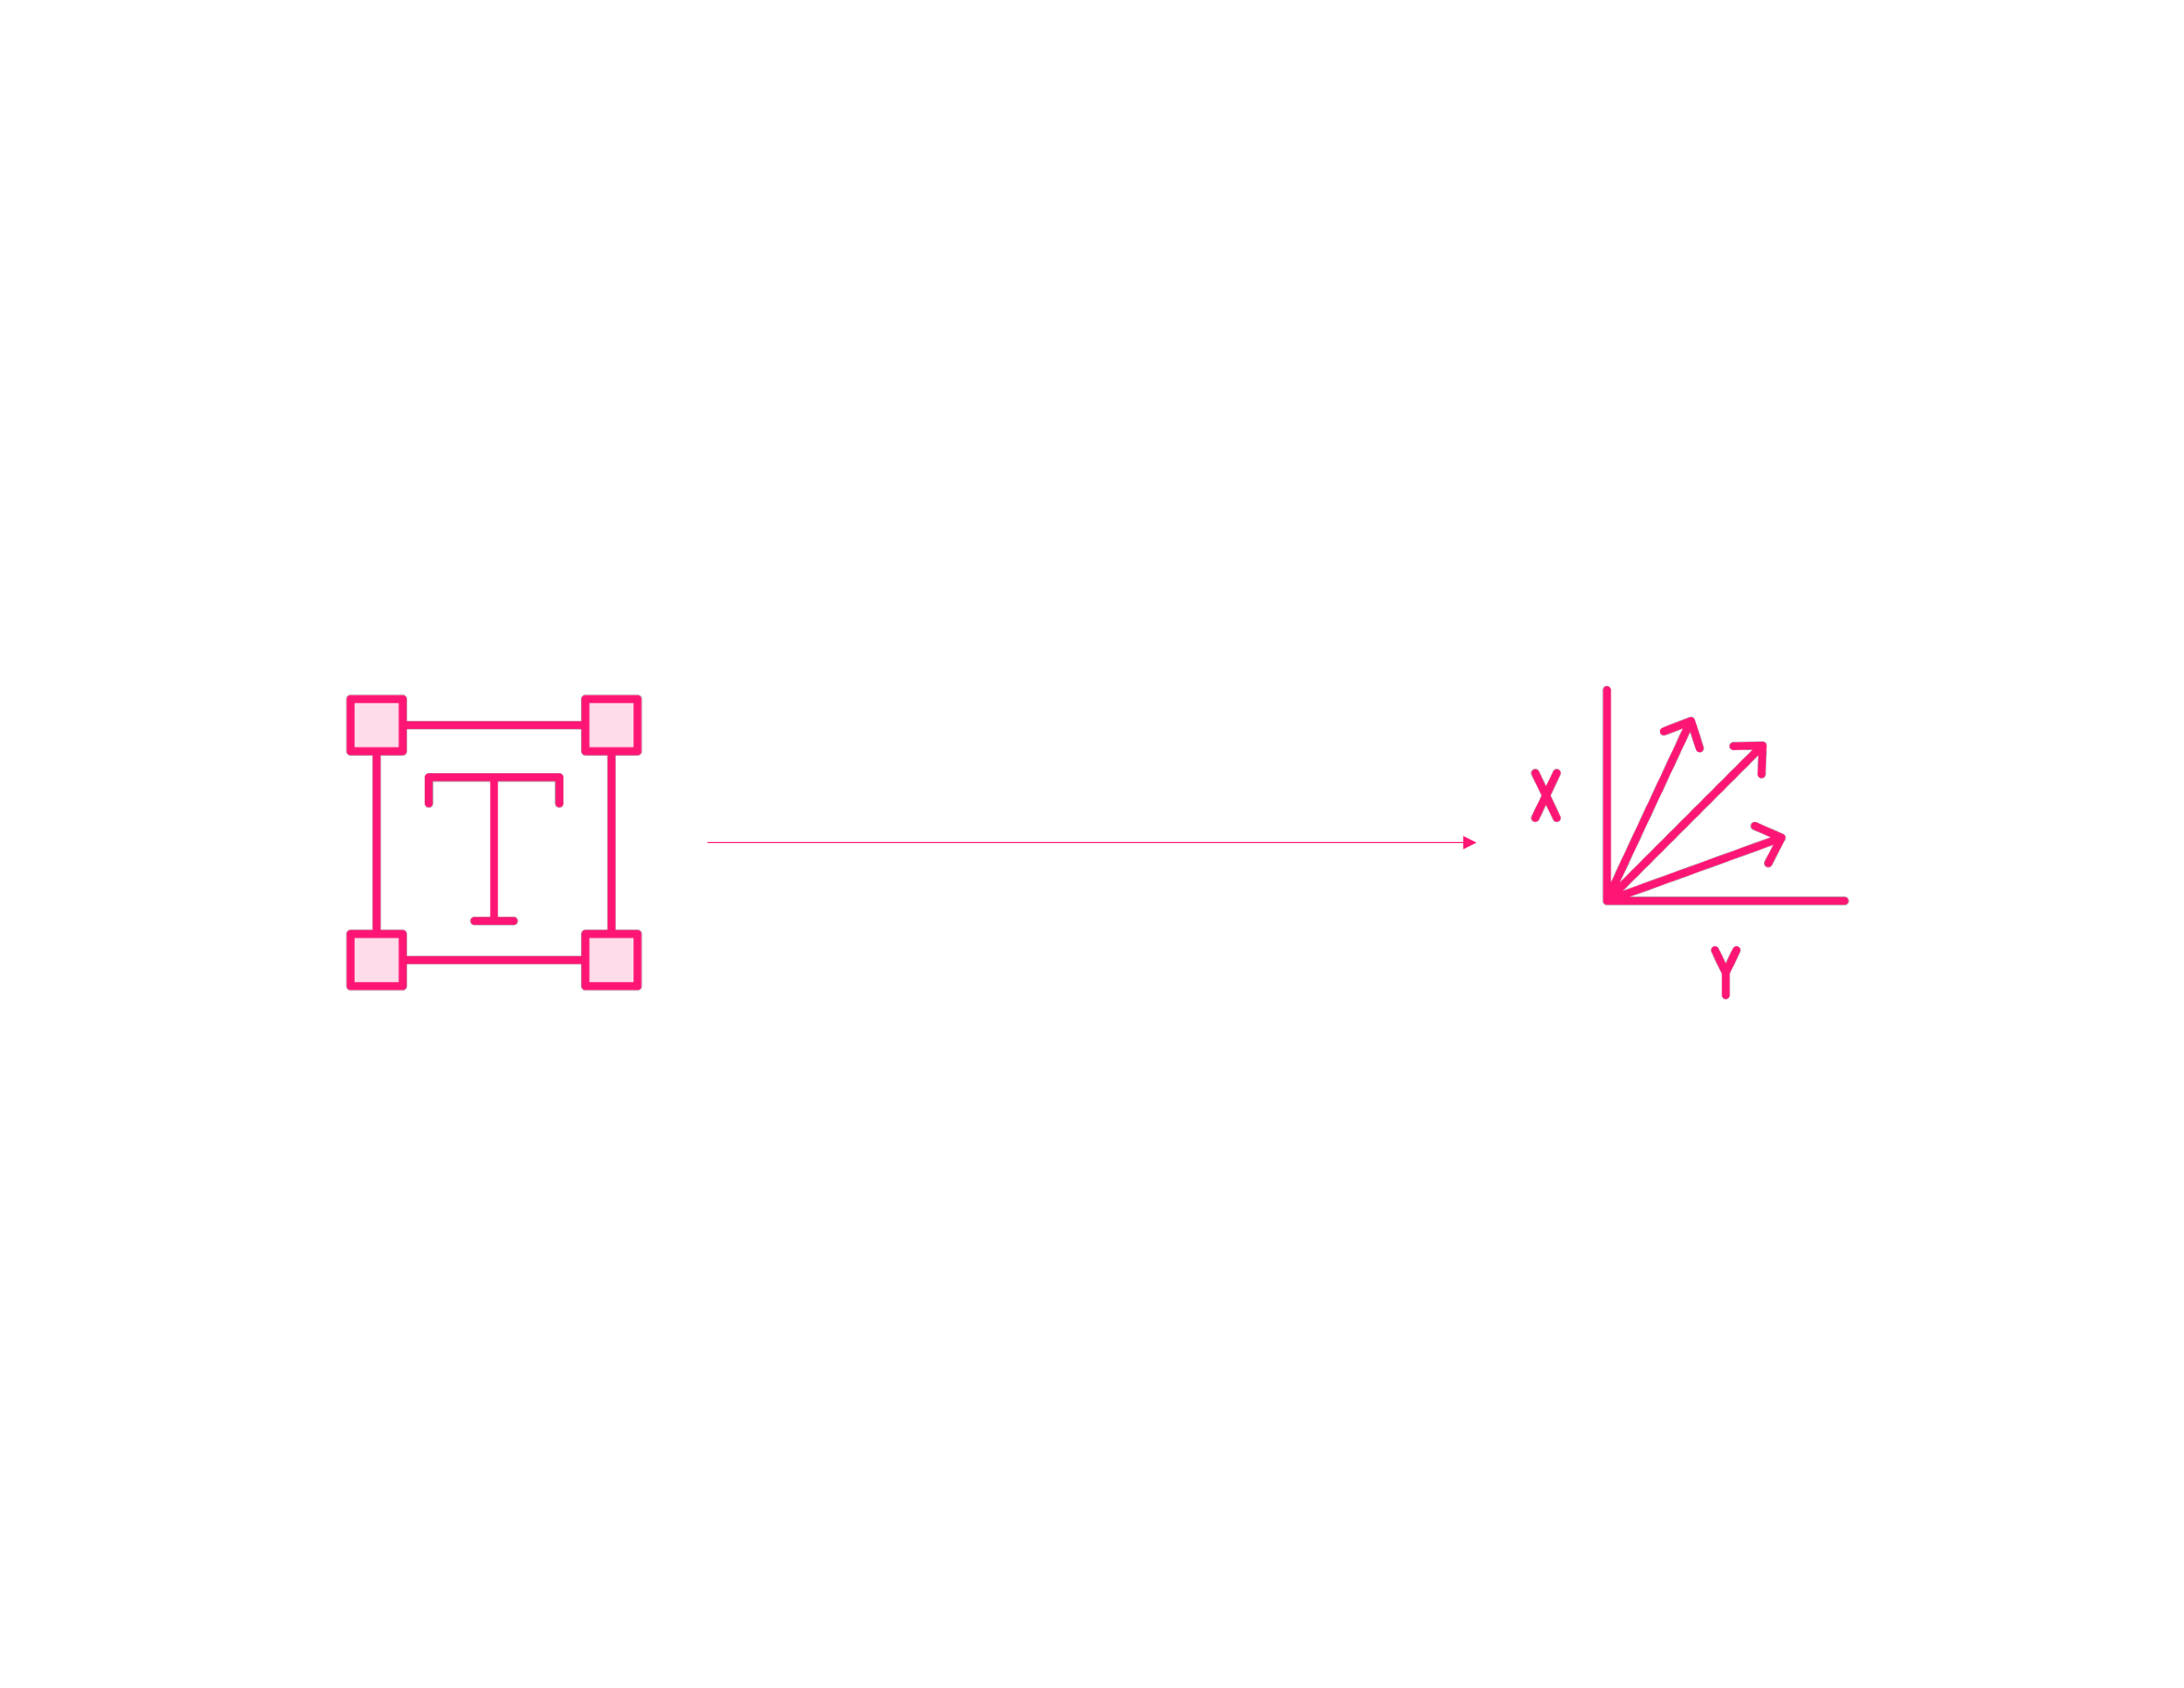

In [2]:
render_diagram(Path("assets/01-text-to-vector-embedding.png"))

Modern embedding models produce vectors in hundreds or thousands of dimensions. Each dimension corresponds to a latent feature learned during training — such as formality, topic, emotional tone, or domain vocabulary.

```
Dimension 1  →  (e.g. formality)
Dimension 2  ↑  (e.g. emotional tone)
Dimension 3  ⊗  (e.g. technical topic)
...
Dimension 768
```

The full pipeline from raw text to a numerical vector looks like this:


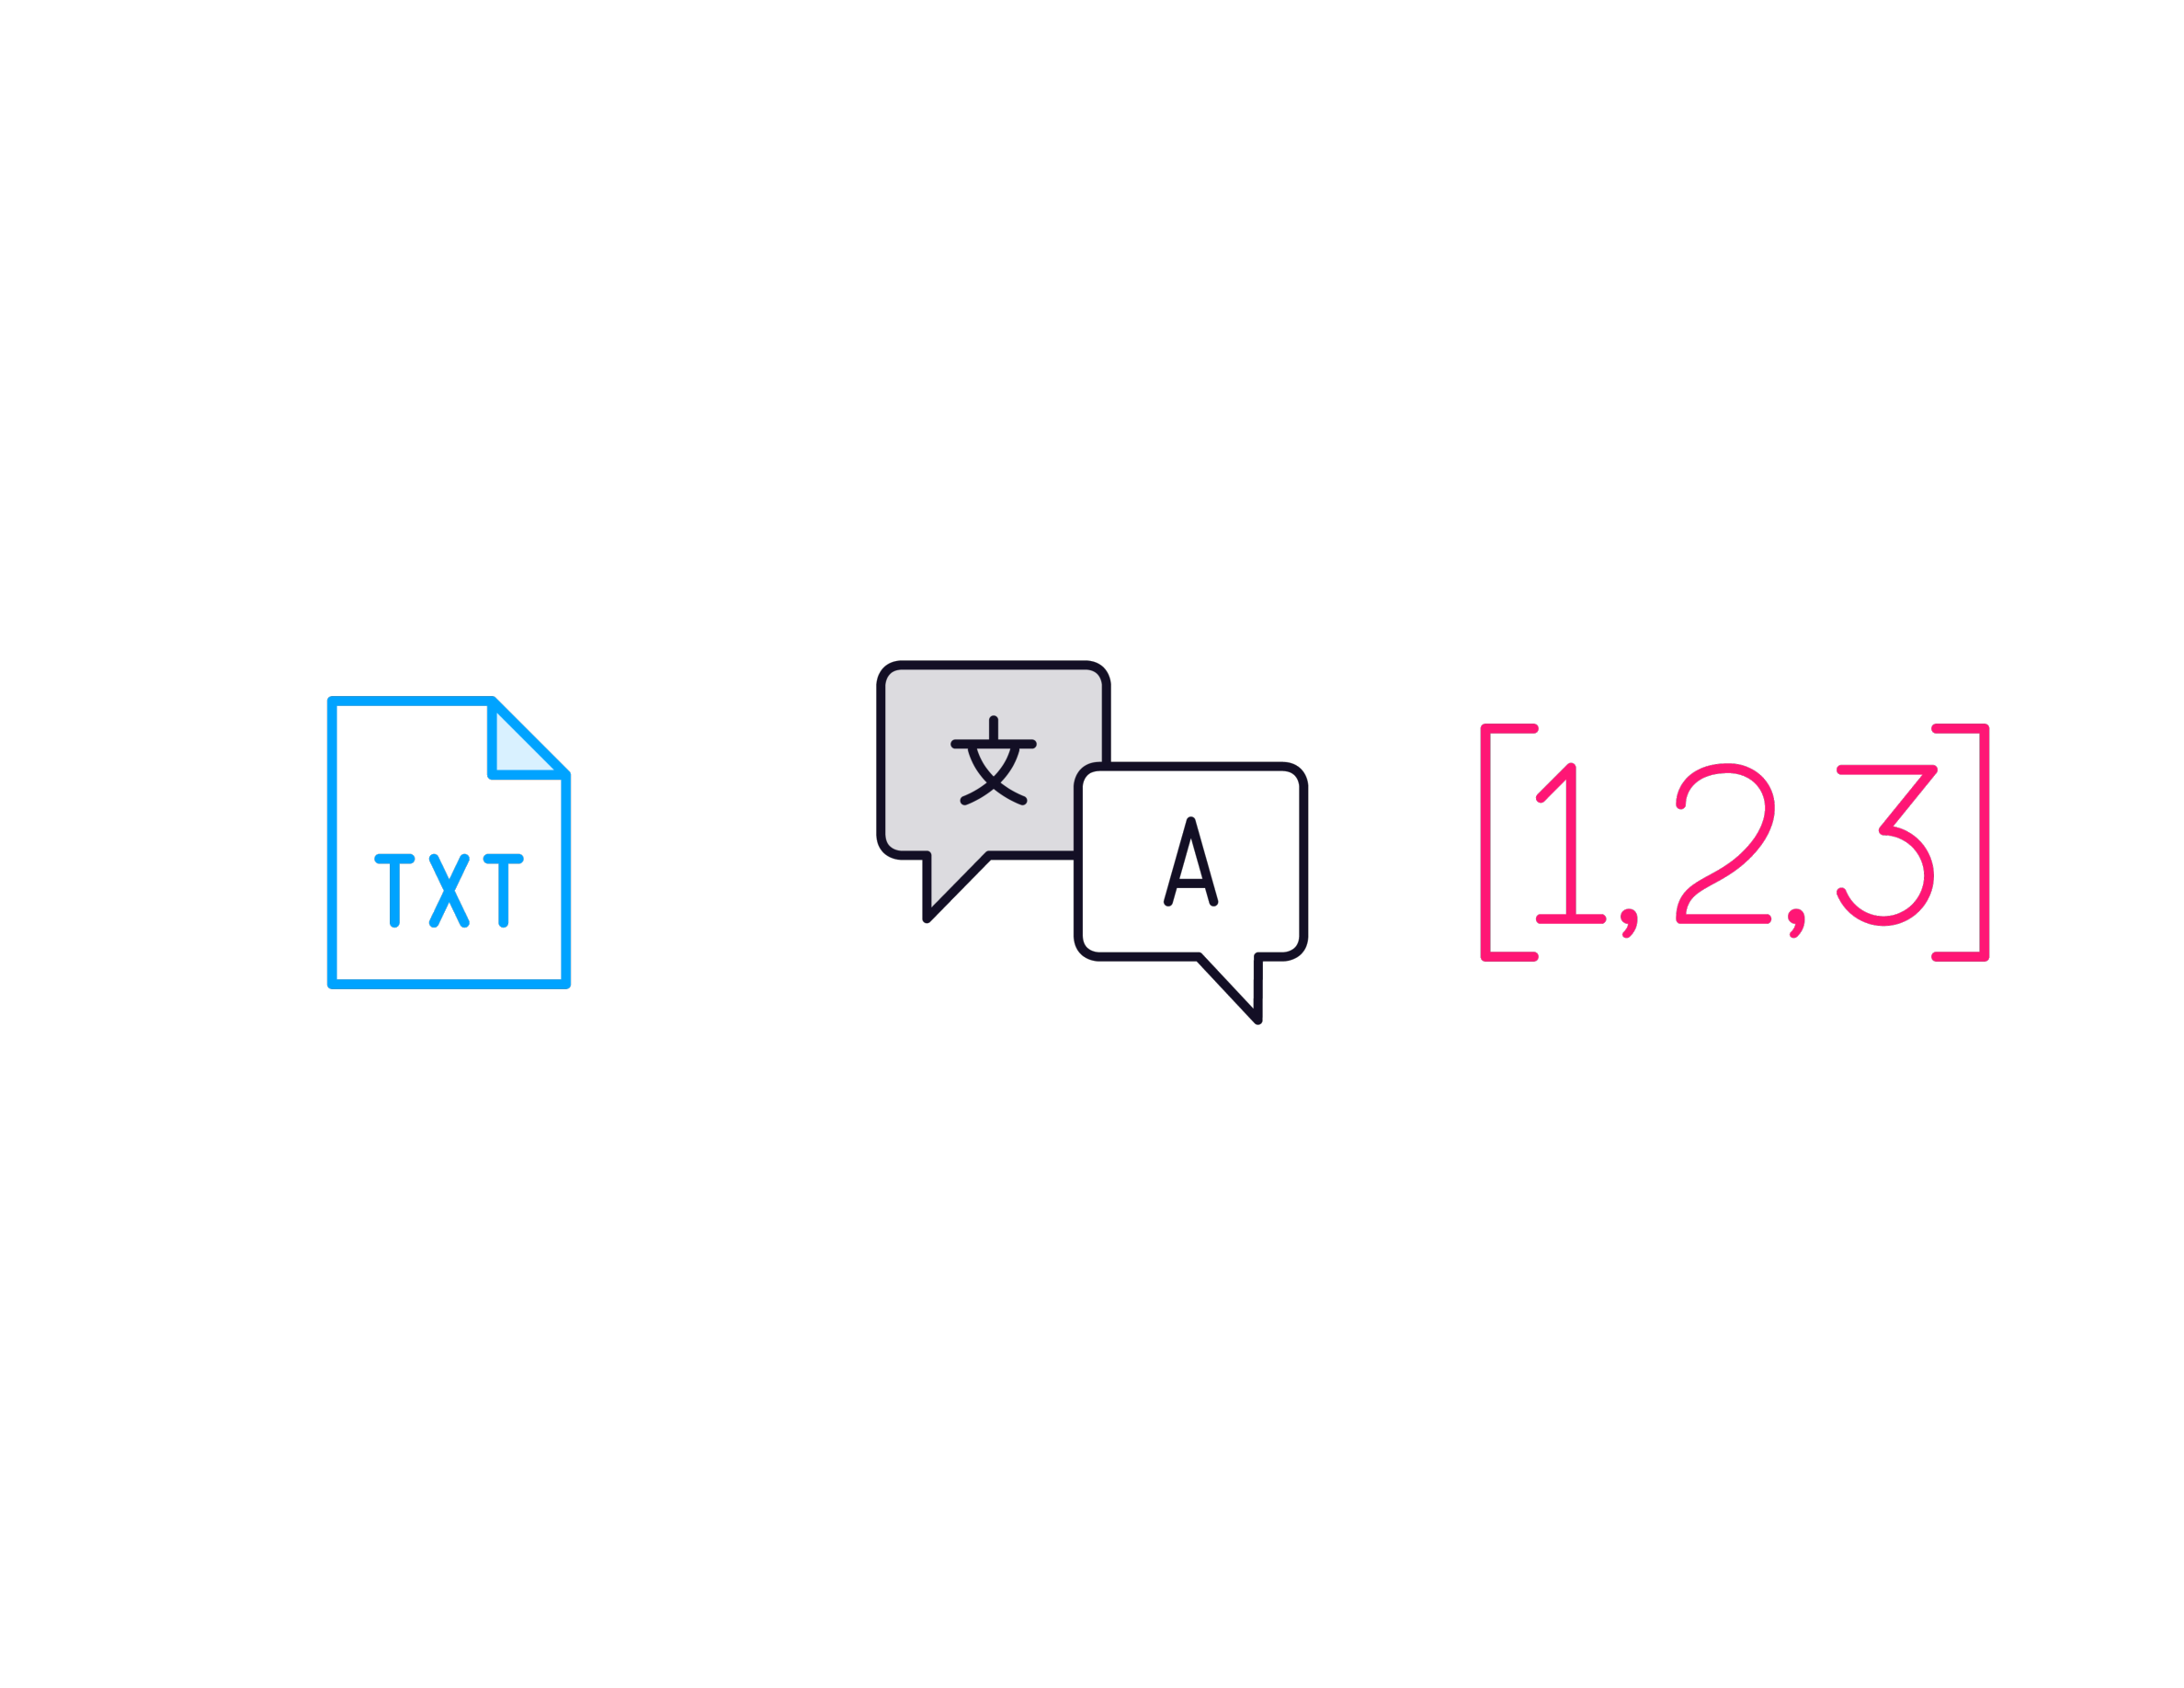

In [3]:
render_diagram(Path("assets/02-embedding-pipeline-txt-model-vector.png"))

### Semantic Arithmetic

The most famous demonstration of embedding quality is the **king – man + woman ≈ queen** arithmetic:

```
King   = [0.8, 0.6, 0.9]
Man    = [0.7, 0.2, 0.4]
Woman  = [0.7, 0.9, 0.4]

King - Man + Woman
  = [0.8-0.7+0.7,  0.6-0.2+0.9,  0.9-0.4+0.4]
  = [0.8, 1.3, 0.9]

Queen ≈ [0.8, 1.25, 0.88]  ✓
```

This only works because the model has learned to encode gender as a consistent linear direction in the vector space. The **direction** of an embedding encodes its semantic content.

### Embeddings in AI Systems

When you query an AI system, it:
1. **Embeds the question** — turns your query into a vector
2. **Navigates the high-dimensional space** — searches for the closest stored vectors
3. **Finds the closest vectors** — retrieves the most relevant documents

Embeddings provide the map that allows an LLM to:
- Access relevant context from a large document corpus
- Draw intelligent inferences based on semantic proximity
- Generate coherent, context-aware responses

### The Mathematics of Semantic Similarity

Three metrics are commonly used to measure how close two vectors are.

#### Euclidean Distance

$$d = \sqrt{(a_1-b_1)^2 + (a_2-b_2)^2 + \cdots + (a_n-b_n)^2}$$

Smaller Euclidean distance means the points are geometrically closer. **Critical flaw for embeddings**: it is highly sensitive to the magnitude (length) of vectors. Two long vectors pointing in roughly the same direction will have a large Euclidean distance even if they are semantically similar.

#### Dot Product

$$A \cdot B = a_1 b_1 + a_2 b_2 + \cdots + a_n b_n$$

The dot product is influenced by **both** the angle and the magnitude of the vectors. Two long vectors with even a vague relationship will yield a large positive dot product — unreliable for pure semantic comparison.

#### Cosine Similarity

$$\cos(\theta) = \frac{A \cdot B}{|A| \cdot |B|}$$

Cosine similarity normalises away magnitude and measures only the **angle** between vectors:
- **1** → vectors point in the same direction (semantically identical)
- **0** → vectors are orthogonal (unrelated)
- **−1** → vectors are diametrically opposed

**Summary**: Euclidean distance and dot product are misled by magnitude. Cosine similarity provides the cleanest measure of semantic alignment — it is the standard choice for most retrieval tasks.

### Understanding Vector Spaces Through Visualisation

Each of the hundreds of dimensions in an embedding vector represents a latent feature learned during training. When you plot a collection of embeddings in 2D (using dimensionality reduction), semantically related concepts cluster together:

```
● "monarch"
     \.
      \.
  O-----------● "king"

"king"      →→→→  (royalty axis)
"engine"    ↑     (mechanical axis)
"blueberry" ↙     (food axis)
```

#### Principal Component Analysis (PCA)

PCA reduces high-dimensional data to 2–3 dimensions for visualisation:
- The **first principal component** is the single direction that captures the greatest variance in the data.
- The **second component** captures the next greatest variance, orthogonal to the first.

Embedding visualisations serve two purposes:
1. **Prove the embedding space is not random** — clusters and directions are meaningful.
2. **Reveal relative positioning** — confirm that your model encodes the right relationships for your domain.

### Comparing Embedding Models

Different models, trained on different data with different objectives, produce different vector representations. The right choice depends on your use case.

#### OpenAI `text-embedding-3`
- Strong general-purpose performance across many tasks.
- Supports **dimension scaling** — you can shorten output vectors with minimal, graceful performance degradation, reducing storage and query cost.

#### Cohere Embed
- Exceptionally robust for enterprise-grade retrieval.
- Optimised not just for similarity, but specifically for finding passages that help an LLM generate better answers (RAG-tuned).

#### BAAI BGE (`BGE-large-en-v1.5`)
- Open-source model from the Beijing Academy of Artificial Intelligence.
- Consistently tops open-source benchmarks such as MTEB.
- Full data control, no API latency, no cost per embedding.

#### Comparison Dimensions

| Dimension | Consideration |
|---|---|
| Performance vs. Cost | API models charge per token; open-source models require GPU compute |
| Dimensionality vs. Efficiency | Higher dimensions → better accuracy, higher storage/memory cost |
| General vs. Domain-Specific | General models work broadly; domain-fine-tuned models excel in specialized corpora |

### Evaluating Embedding Quality: MTEB

The **Massive Text Embedding Benchmark (MTEB)** is the standardised test for embedding models. It evaluates a model across a battery of diverse tasks:

| MTEB Category | What It Tests |
|---|---|
| **Retrieval** | Find the most relevant document given a query; scored by MAP and nDCG |
| **Clustering** | Group semantically similar texts together |
| **Classification** | Assign a text to the correct label |
| **Semantic Textual Similarity** | Score pairwise semantic closeness |
| **Reranking & Pair Classification** | Re-order candidates or classify sentence pairs |

#### Retrieval Metrics

- **Mean Average Precision (MAP)** — rewards systems that rank the most relevant documents higher.
- **Normalized Discounted Cumulative Gain (nDCG)** — accounts for the position of relevant results; a relevant doc at rank 1 scores higher than the same doc at rank 5.
- **Precision@K** — fraction of top-K results that are relevant.
- **Recall@K** — fraction of all relevant results captured in the top K.

> MTEB is the starting point for model selection, not the end. Always evaluate on your own domain data before committing to a model.

### Demos: Embeddings in Practice

**Demo: Generating Embeddings at Scale** — Generating embeddings for a real document collection using OpenAI's API with chunking, retry logic, and rate limiting.

**Demo: Building Robust Embedding Pipelines** — Improving chunking integration, handling rate limits with exponential backoff, caching embeddings to avoid redundant API calls, and optimising cost.

**Demo: Semantic Similarity Search in Practice** — Query formulation, retrieval ranking, and relevance tuning.

See [`01-embeddings-demos/`](01-embeddings-demos/) for the full project.

In [4]:
# From 01-embeddings-demos/clip_6_embeddings-demo.py
# Batch embedding with retry and rate-limit handling

# from langchain_openai import OpenAIEmbeddings
# from tenacity import retry, stop_after_attempt, wait_exponential
# from langchain.text_splitter import RecursiveCharacterTextSplitter

# embeddings = OpenAIEmbeddings(model="text-embedding-3-small", dimensions=256)

# @retry(stop=stop_after_attempt(3), wait=wait_exponential(min=1, max=10))
# def embed_batch(texts: list[str]) -> list[list[float]]:
#     return embeddings.embed_documents(texts)

<a id="module-02"></a>

## Module 02: Vector Database Architecture and Operations

_Covers why vector databases exist, how HNSW and other indexing algorithms work, storage strategies for scale, a comparison of leading solutions, schema design patterns, and production operations._

### Why Traditional Databases Fall Short

Traditional databases excel at exact matches and are optimised for one-dimensional lookups. They cannot efficiently answer the question: *"find the closest vectors to this query vector in a space with hundreds of dimensions"*.

Calculating cosine similarity or Euclidean distance across millions of high-dimensional vectors is computationally prohibitive. Traditional B-tree indexes offer no acceleration for nearest-neighbour search.

**Vector databases** solve this by:
1. Storing dense vectors alongside payloads.
2. Performing fast **Approximate Nearest Neighbour (ANN)** search.
3. Creating indexes that build efficient shortcuts and hierarchies.

### HNSW: Hierarchical Navigable Small World

HNSW solves a deceptively simple problem: how do you find the closest point in a million-point dataset without checking every single point?

It builds a multi-layer graph where:
- The **top layers** contain few nodes with long-range connections — useful for fast global navigation.
- The **bottom layer** contains all nodes with short-range connections — useful for local precision.

Search starts at the top and greedily descends toward the query vector:


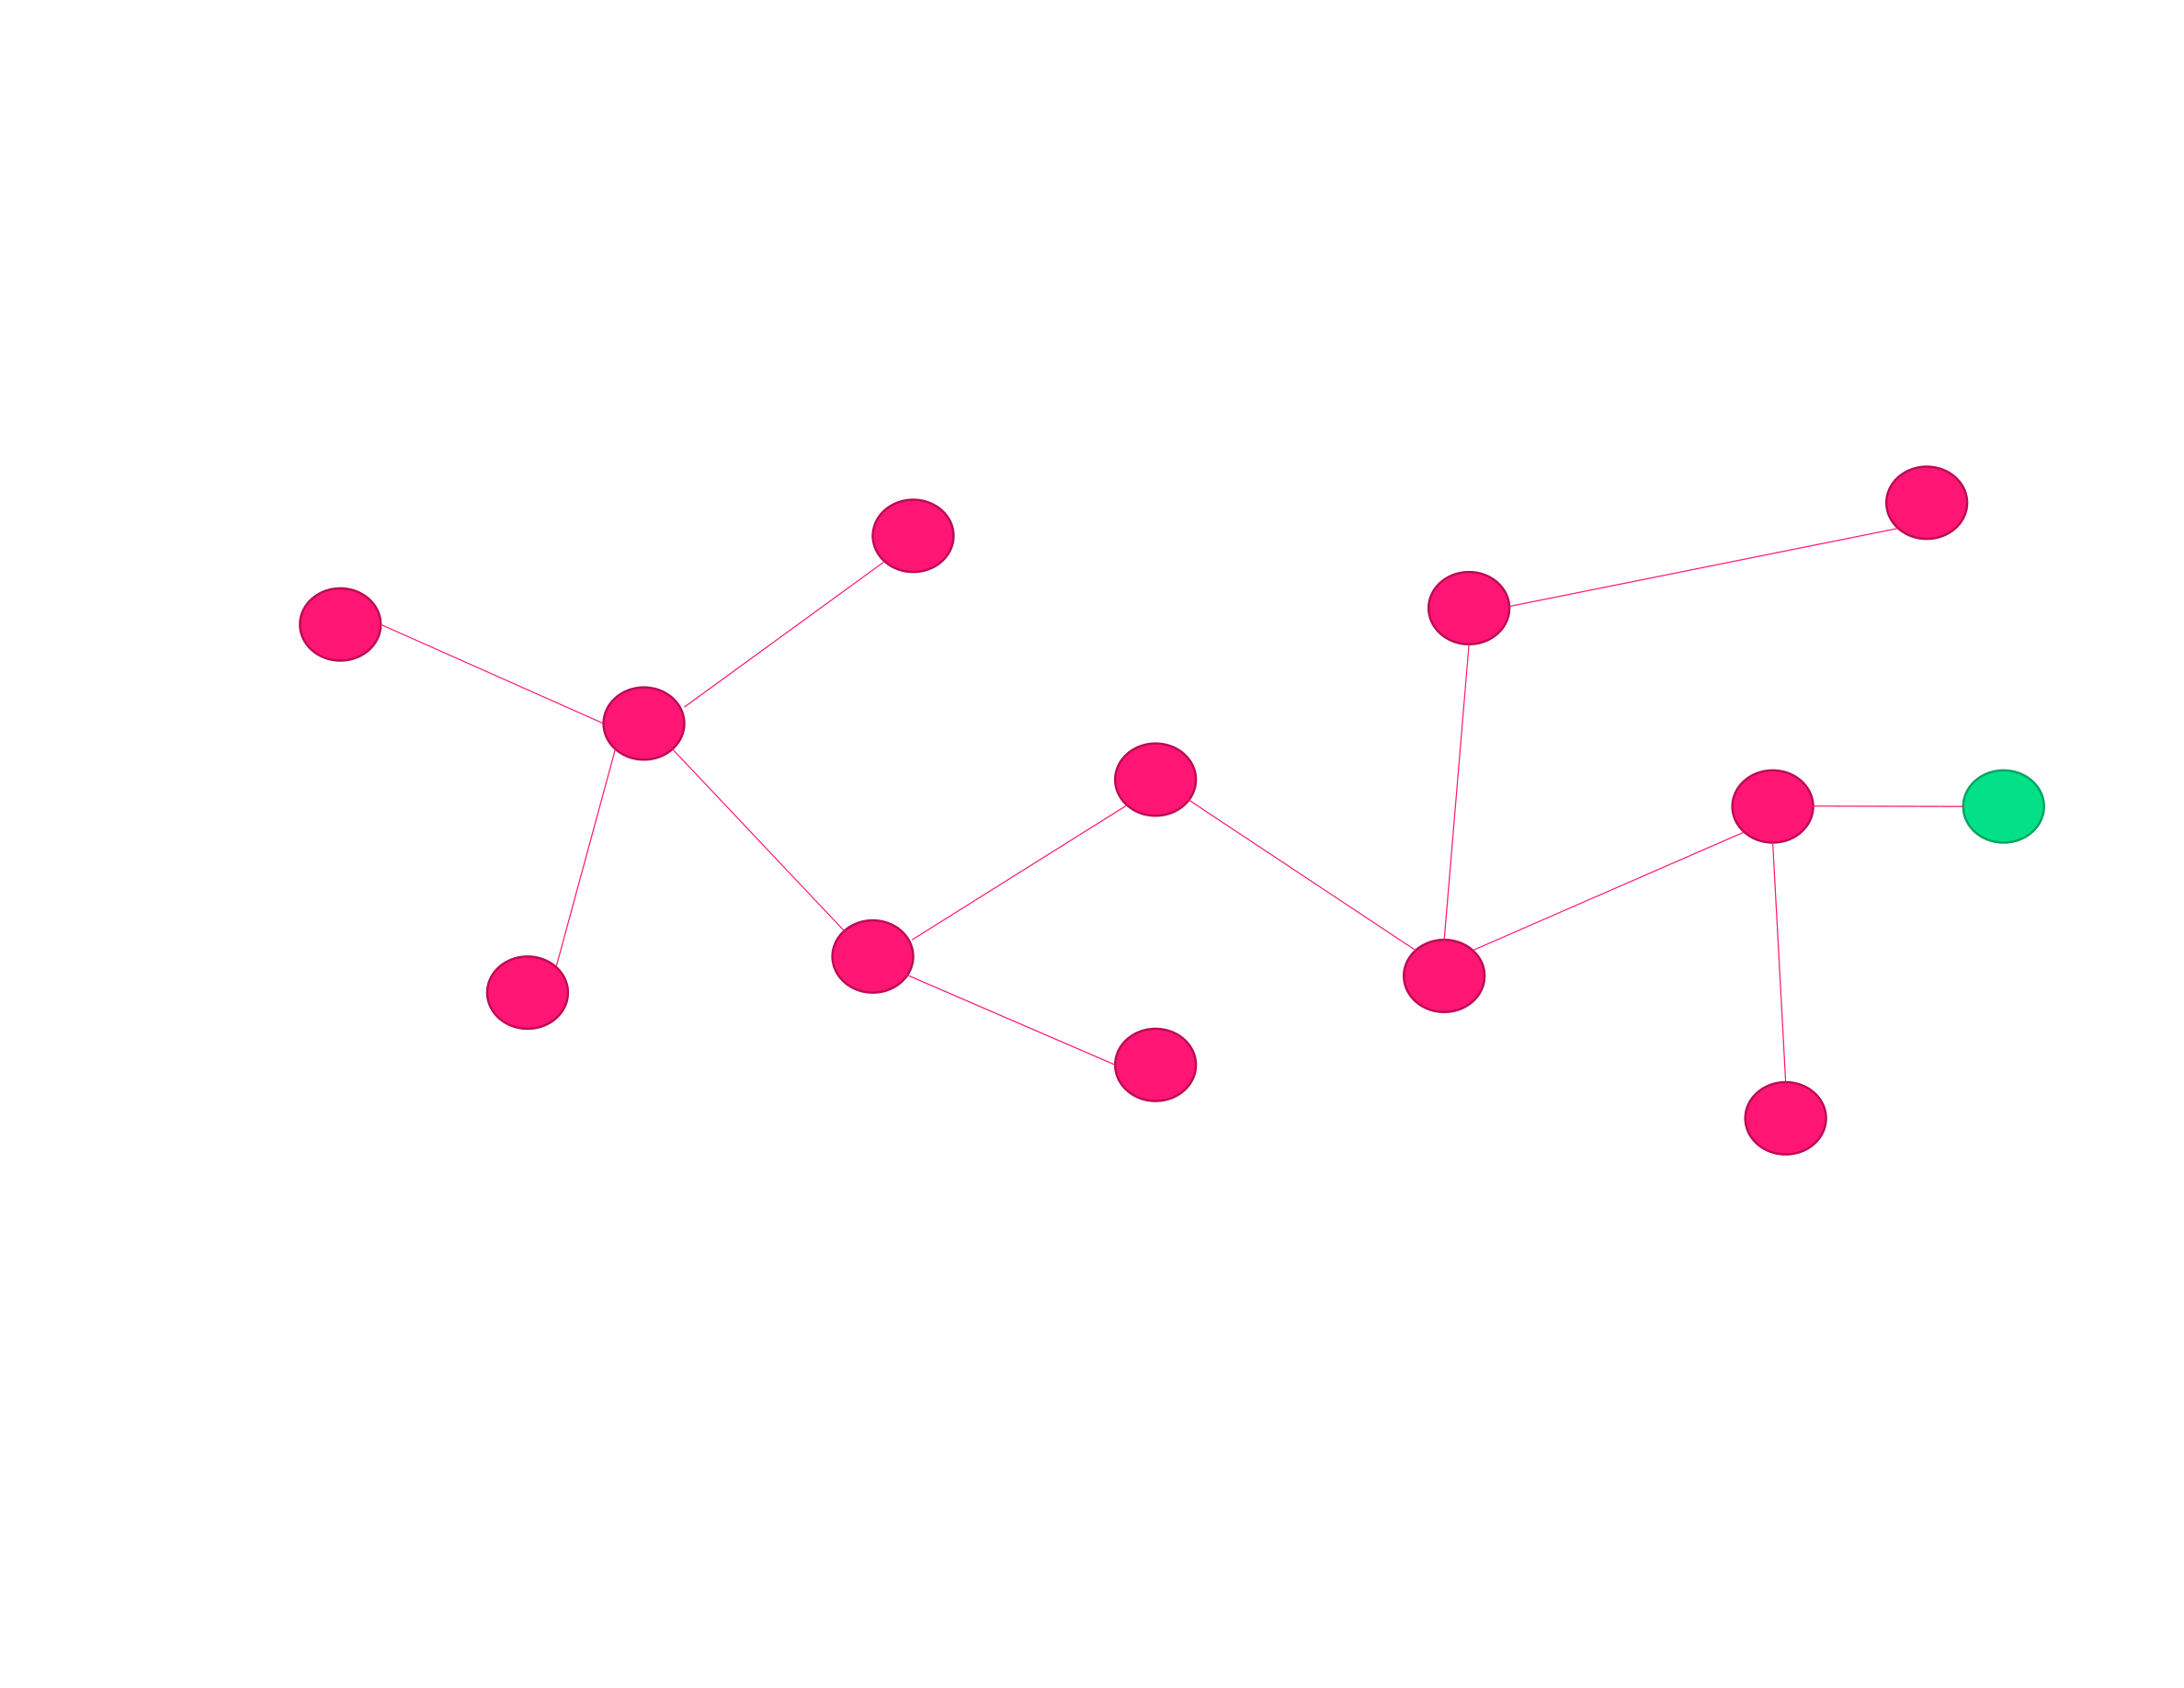

In [5]:
render_diagram(Path("assets/03-hnsw-flat-graph.png"))


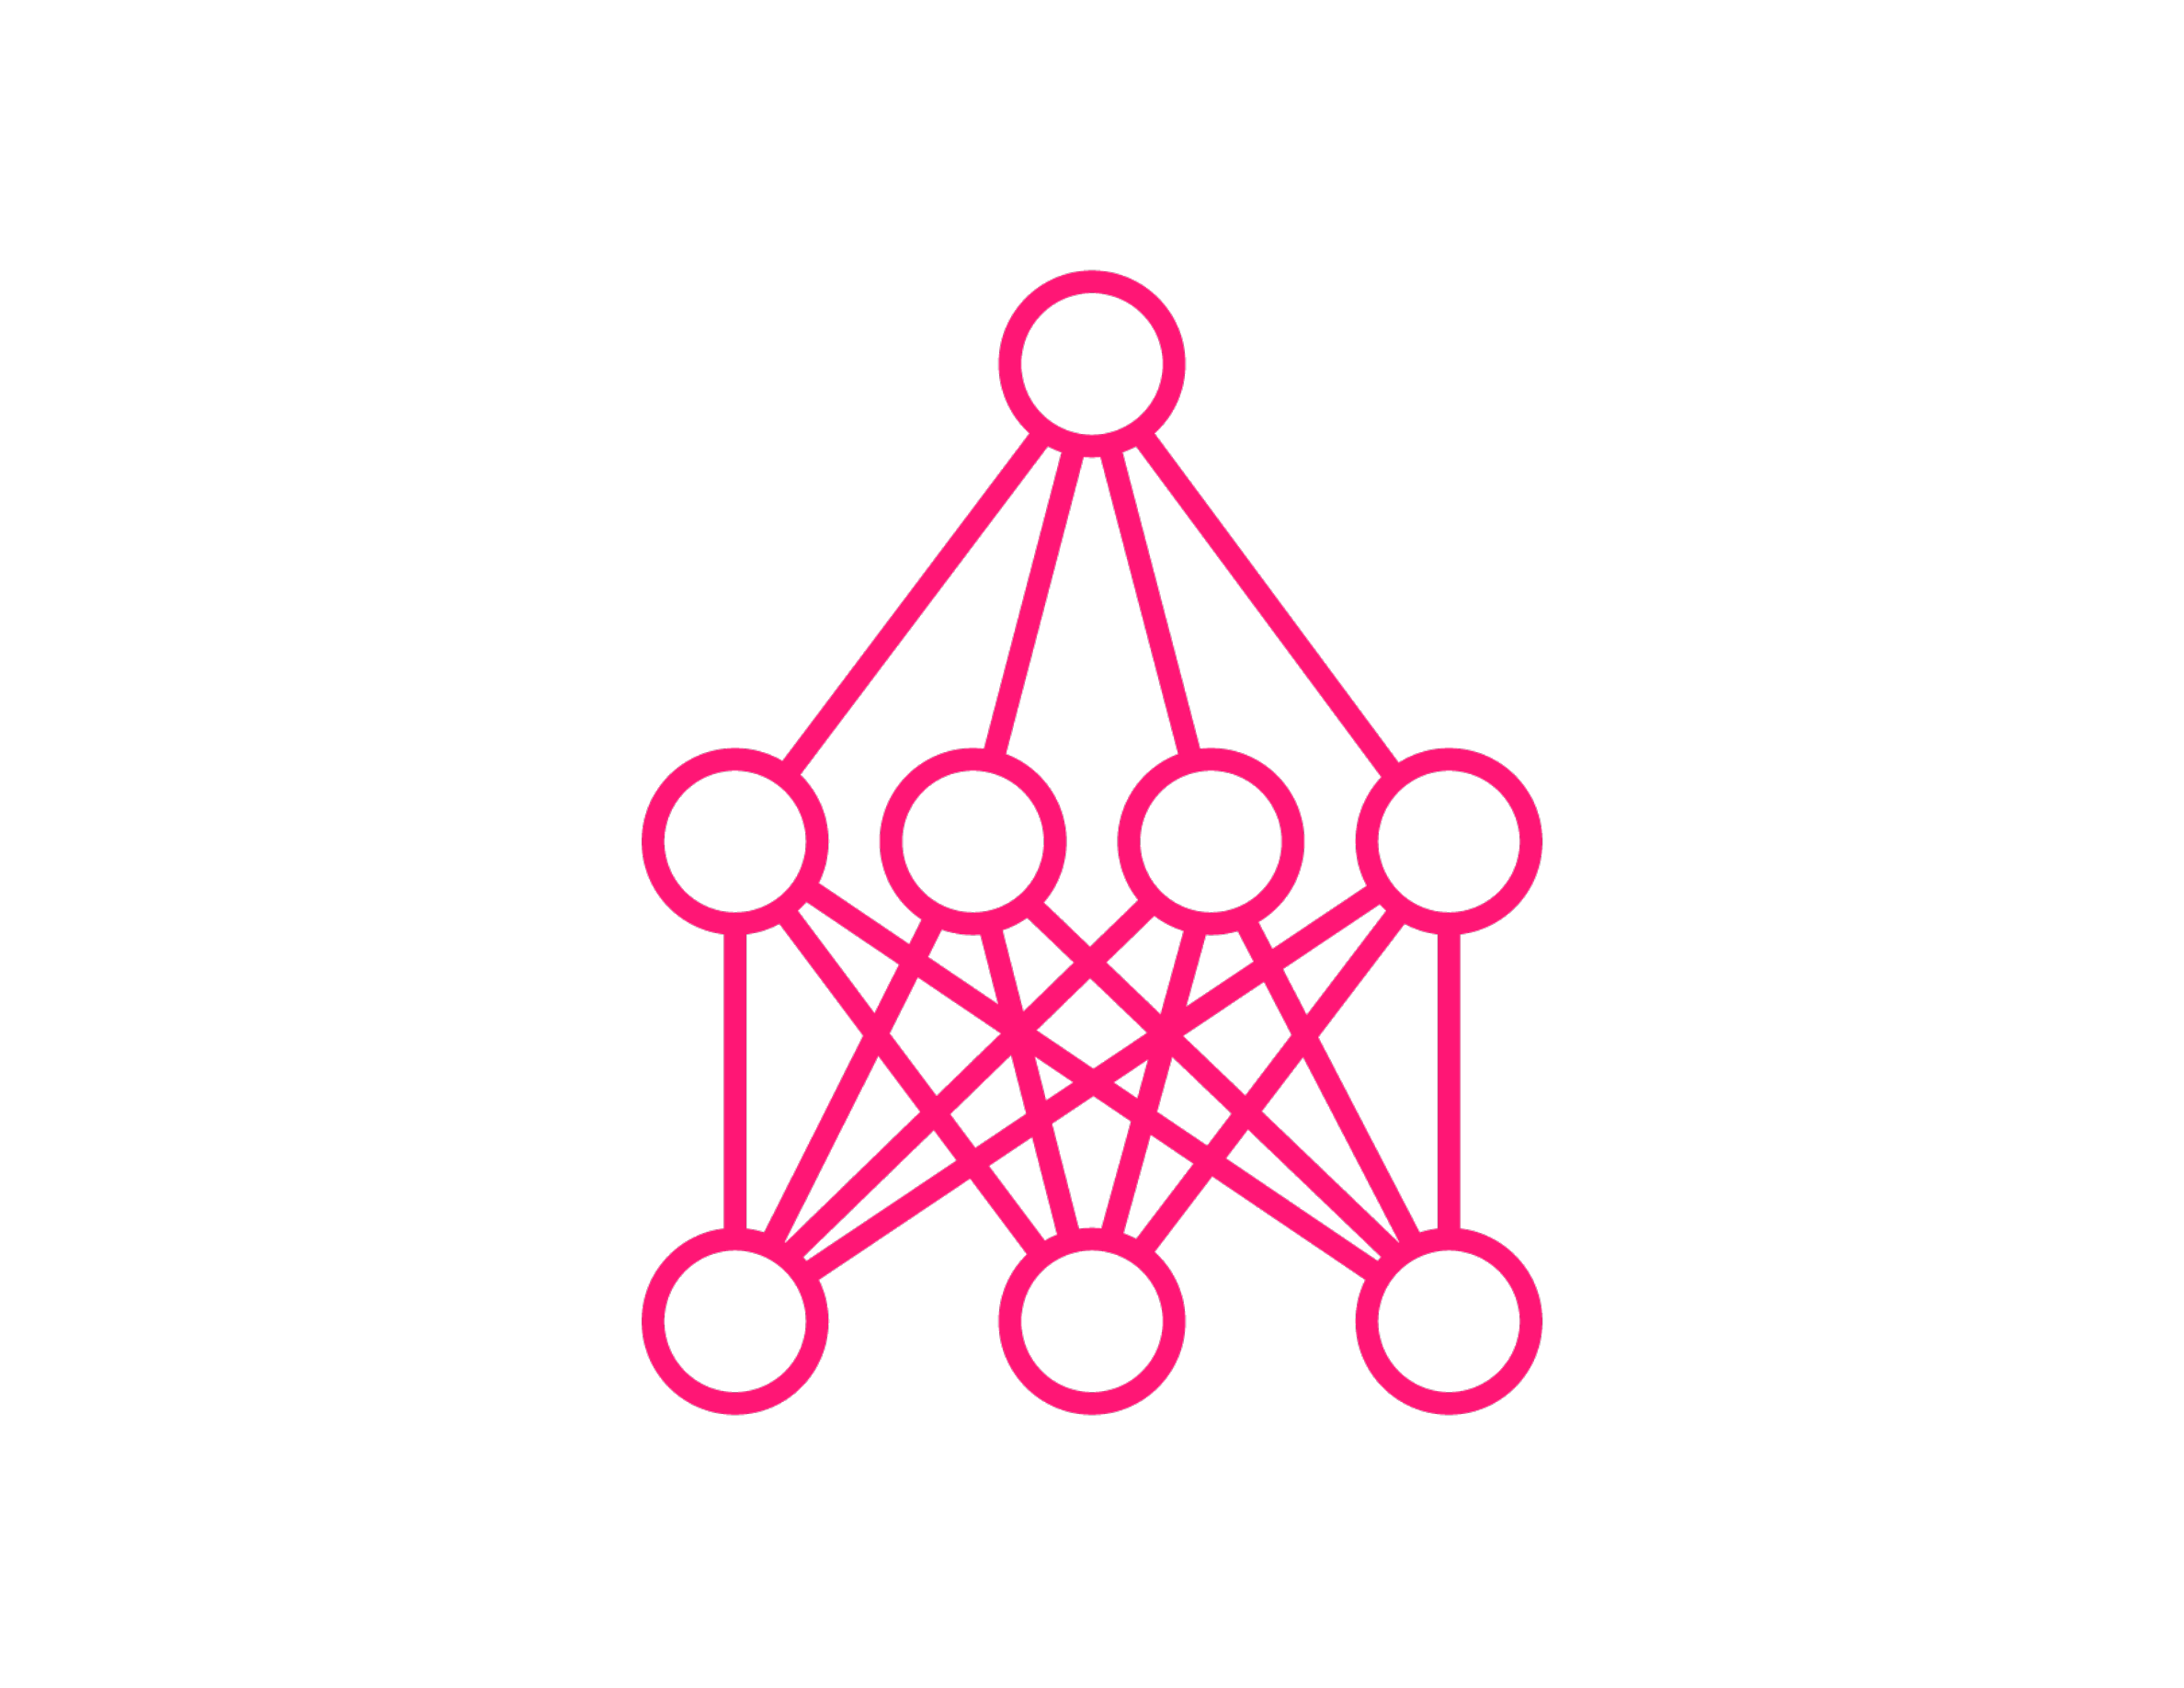

In [6]:
render_diagram(Path("assets/04-hnsw-hierarchical-layers.png"))


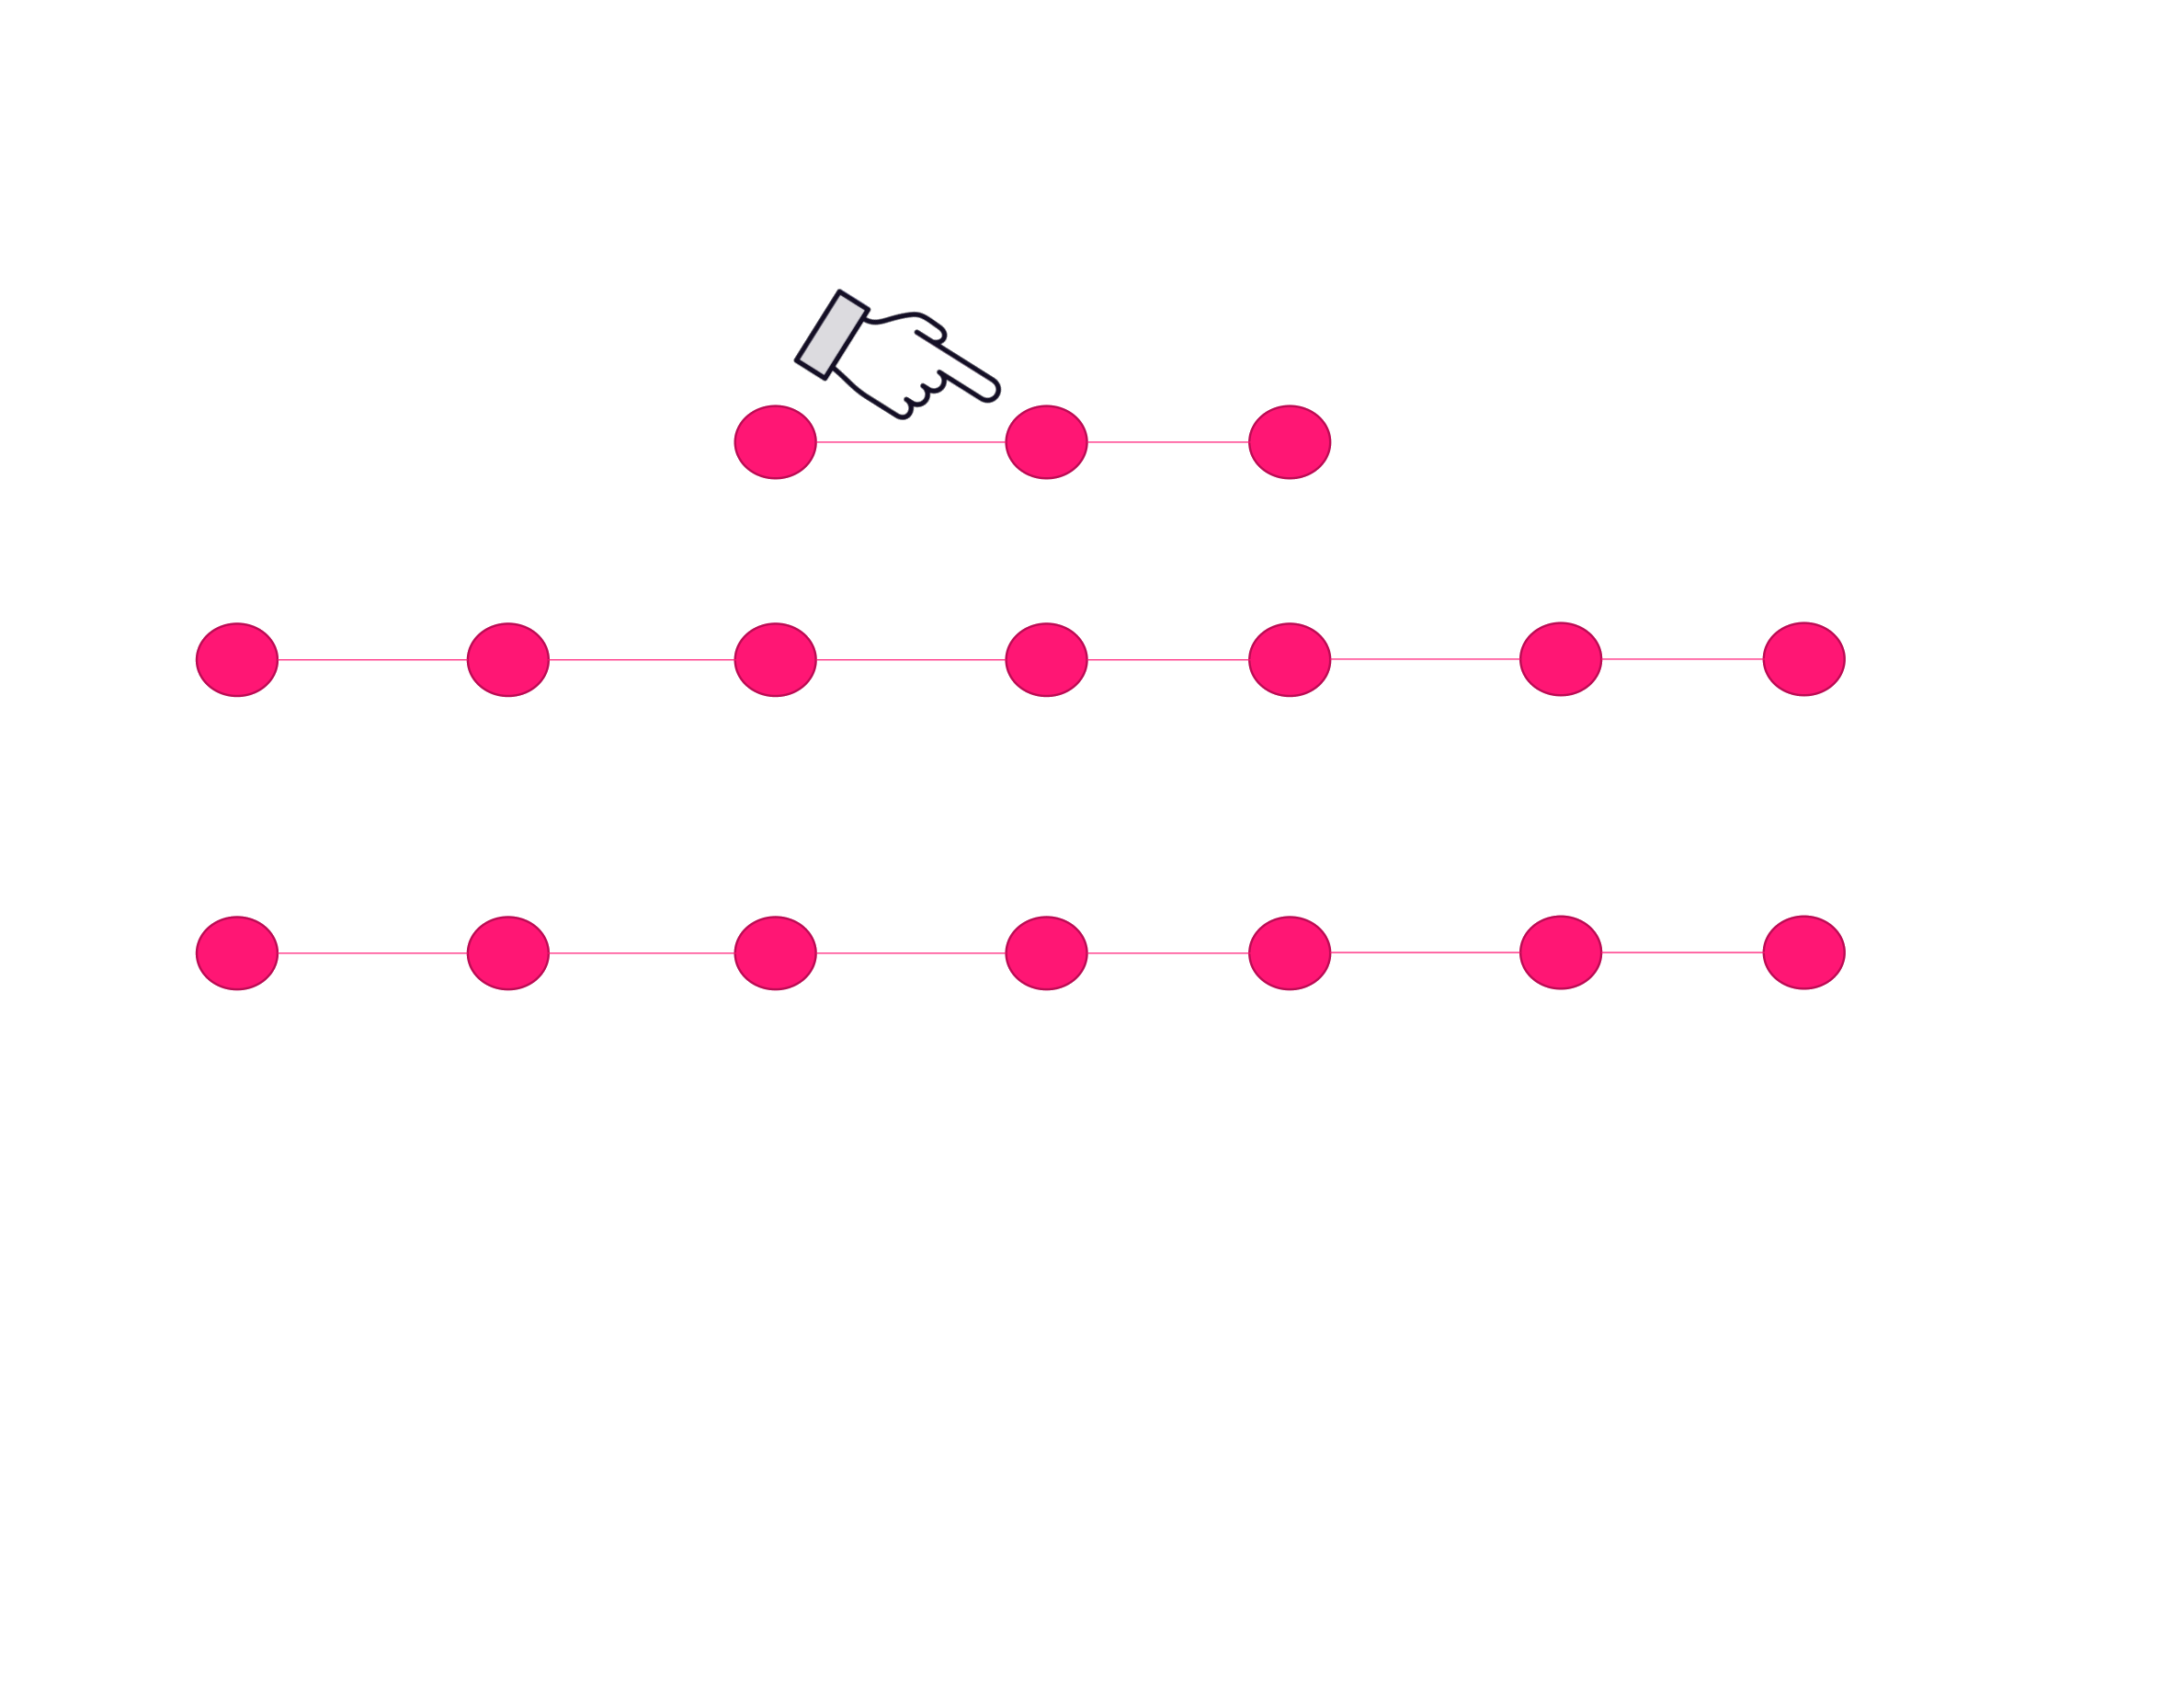

In [7]:
render_diagram(Path("assets/05-hnsw-entry-point-search.png"))

#### HNSW Trade-offs

**Why HNSW wins:**
- Delivers exceptional recall at low latency.
- Balances speed, accuracy, and ease of use.

**HNSW drawbacks:**
- Consumes significant RAM — the entire graph must be in memory.
- Has construction parameters that must be tuned:
  - `M` — maximum number of connections per node
  - `efConstruction` — how thoroughly the graph is built during index creation

### Other Indexing Algorithms

#### Inverted File Indexing (IVF)

IVF splits vectors into clusters (Voronoi cells) using centroids:
- Similar vectors are stored together in cells.
- At query time, only the closest clusters (`n_probe` cells) are searched, not the entire dataset.
- **Lower `n_probe`** → faster search, lower recall.
- **Higher `n_probe`** → better accuracy, more computation.

IVF dramatically reduces comparisons but full distance calculations remain costly within each cluster.

#### Product Quantization (PQ)

PQ compresses vectors to reduce memory and accelerate search:
1. Split each high-dimensional vector into `M` subvectors.
2. Compress each subvector using small centroid codebooks.
3. Replace each subvector with a centroid ID (turning float vectors into compact integer codes).
4. Approximate distances using precomputed lookup tables.

PQ reduces memory usage by **10–20×** with a small accuracy trade-off.

#### IVF vs. PQ

| | Inverted File Indexing (IVF) | Product Quantization (PQ) |
|---|---|---|
| **Strategy** | Reduces number of vectors examined | Compresses the vectors themselves |
| **Changes** | Search structure (partitions dataset into cells) | Data representation (encodes vectors into compact codes) |
| **Control** | Direct control via `n_probe` | Trades accuracy for memory and speed |
| **Dataset in play** | Searches a subset | Keeps full dataset but compressed |

In production, IVF and PQ are frequently combined (e.g., `FAISS` uses `IVF+PQ` or `HNSW+PQ`).

### Storage Strategies for Scale

#### In-Memory Storage
The simplest solution is to keep everything in RAM. Pure in-memory vector databases deliver blazing latency but cost scales quickly: storing one billion 1536-dimensional float32 vectors consumes roughly **6 terabytes** of memory.

#### Disk-based Storage
- Store vectors on SSD (or HDD).
- Reduces cost but introduces I/O latency.
- Qdrant and Weaviate use **memory mapping** (`mmap`) to treat disk files as if they were in memory — the OS handles paging.

#### Compression

A 768-dimensional float32 vector occupies **3 kilobytes**. Quantisation shrinks this dramatically:

| Technique | Description | Compression Ratio |
|---|---|---|
| **Scalar quantization** | Convert 32-bit floats to 8-bit integers | 4× |
| **Binary quantization** | Convert to single bits | 32× |
| **Product quantization** | Compress subvectors with codebooks | 10–20× |

#### Sharding

Splits vector data across multiple nodes — each node is responsible for a subset:

| Approach | Description |
|---|---|
| **Horizontal sharding** | Partition based on vector ID or metadata |
| **Replication-based sharding** | Each node holds a full copy of the entire index |
| **Partitioned sharding** | Semantically similar vectors colocate on the same node |

#### Replication
Achieves availability and read scaling but introduces consistency challenges.

> **A typical production deployment** uses memory-mapped disk storage with PQ compression, sharded across 16 nodes, each with 2 replicas for high availability.

### Vector Database Comparison

#### Pinecone
Fully managed cloud service. Simple setup, handles scaling/replication/index optimisation automatically. Trade-off: vendor lock-in and minimal control over underlying configuration.

#### Weaviate
Open-source with a cloud offering. Full-featured search engine supporting rich metadata filtering and hybrid search. Resource-intensive.

#### Qdrant
Exceptional speed and memory efficiency. Offers fine-grained control over indexing parameters. Trade-off: higher operational complexity.

#### Chroma
Deeply embedded in the Python ecosystem. Lightweight, runs embedded within your application. Built for local development and small-to-medium workloads — not designed for petabyte-scale or distributed systems.

#### Choosing the Right Tool

| Use Case | Recommended Tool |
|---|---|
| Local experiments / prototyping | Chroma |
| Cost and performance optimisation | Qdrant |
| Production MVP (need to move fast) | Pinecone |
| Filtering and hybrid search | Weaviate |

### pgvector and Self-hosted Solutions

#### pgvector

A PostgreSQL extension that adds vector data types and similarity search operators:

```sql
-- Define a vector column
CREATE TABLE embeddings (id SERIAL, vector vector(1536));

-- Cosine similarity search
SELECT * FROM embeddings
ORDER BY vector <=> '[0.1, 0.2, ...]'::vector
LIMIT 10;
```

**Advantages**: Simple setup; backups, replication, and high availability handled by PostgreSQL; supports IVFFlat and HNSW indexes.

**Limitations**: Single-node by nature; index build times grow with dataset size; complex filters can degrade performance.

#### Self-hosted vs. Managed Services

| | Self-hosted | Managed Services |
|---|---|---|
| **Data ownership** | You own it completely | Subject to provider terms |
| **Cost** | Pay your cloud provider's hardware cost | Pay a 5–10× premium over raw infrastructure |
| **Operations** | You handle backups, upgrades, scaling, monitoring, DR | They handle replication, automatic scaling, uptime SLAs |

**Decision guide**:
- **pgvector** — already deep in PostgreSQL and want simplicity.
- **Chroma** — prototyping and local experimentation.
- **Managed services** — need to move fast, lack ops bandwidth, or anticipate massive scale.

### Designing Vector Database Schemas

#### Metadata Filtering

Most vector databases let you attach arbitrary key-value pairs to each vector and combine semantic search with structured filtering in one operation.

- **Pre-filtering** — apply filters before the ANN search. Faster, but can miss relevant results if filters are too restrictive.
- **Post-filtering** — apply filters after the ANN search. More accurate but slower.

#### Namespace Organisation

Namespaces let you isolate data and maintain separate indexes for different embedding model versions side by side — useful during model migrations.

#### Hybrid Search Configuration

Hybrid search merges semantic similarity with traditional keyword matching:
- Store both **embeddings** and **full text** in the schema.
- Configure how much weight each signal carries.
- Specify which fields are searchable by keyword and how the fusion algorithm combines scores.

### Advanced Query Patterns in Practice

#### Metadata-filtered Search

Scenario: a support bot for a SaaS product with versioned documentation. A user asks about "login issues" on version 2.5 — you need semantic search *constrained* to their version.

In [8]:
# Qdrant metadata-filtered search
# from qdrant_client import QdrantClient
# from qdrant_client import models

# results = client.search(
#     collection_name="docs",
#     query_vector=embedding,
#     query_filter=models.Filter(
#         must=[
#             models.FieldCondition(key="version", match=models.MatchValue(value="2.5")),
#             models.FieldCondition(key="date", range=models.Range(gte="2024-01-01"))
#         ]
#     ),
#     limit=10
# )

#### Multi-vector Retrieval for Rich Documents

Instead of embedding a whole document as one vector, index each semantically distinct chunk separately — even chunks of different types (text, table, image caption) from the same document:

In [9]:
# Index time: one document, multiple vectors
chunks = [
    {"text": "Introduction to transformers", "doc_id": "paper123", "type": "text"},
    {"text": "Table: Model accuracy comparison", "doc_id": "paper123", "type": "table"},
    {"text": "Figure: Attention mechanism", "doc_id": "paper123", "type": "image_caption"}
]

# Query time: retrieve across types, then group by document
# results = vector_db.search(query, limit=5)
# doc_groups = group_by_doc_id(results)
# → Most relevant chunks from the most relevant documents

### Production Operations

#### Incremental Updates
- Use real-time **upserts** rather than full index rebuilds.
- HNSW supports dynamic insertion — new vectors are added without rebuilding the entire graph.
- Plan for **deletions** and update frequency: tombstoning deleted vectors and scheduling periodic cleanup.

#### Batch Operations
- Batch inserts are essential for scale — avoid inserting vectors one by one.
- Batching improves index quality (HNSW can form better connections when nodes are inserted together).
- Optimise batch size and monitor memory usage during bulk loads.

#### Index Rebuild Strategies
- Indexes degrade over time as data distribution shifts.
- Use **blue-green deployments** for zero-downtime index rebuilds: build a new index, validate it, then flip traffic.

#### Downtime Minimisation
- Replication
- Rolling upgrades
- Blue-green rebuilds
- Health checks and automatic failover

#### Monitoring Index Health
- Track vector count and growth rate.
- Monitor index size versus raw vector size (ratio indicates compression effectiveness).
- Watch query latency percentiles (P50, P95, P99).
- Track recall rate to detect index degradation.

#### Backup and Recovery
- Dump vectors and metadata to object storage (e.g., S3).
- Use snapshot-based backups for consistent point-in-time recovery.
- Store backups with versioning.
- Document and practise your recovery procedure quarterly.

#### Performance Debugging
- Monitor index construction parameters — mistuned `M` or `efConstruction` degrades recall.
- Watch for metadata filters that widen to full scans.
- Monitor resource usage: RAM, CPU, and I/O per node.

<a id="module-03"></a>

## Module 03: Knowledge Graphs and Structured Knowledge

_Covers what knowledge graphs are, how they differ from vector stores and relational databases, ontology design, entity extraction from text, relation extraction, building graphs with LLMs, graph embeddings, hybrid vector+graph retrieval, and graph maintenance._

### What Is a Knowledge Graph?

A knowledge graph is a data model that represents information as a **network of entities and the relationships between them** — a web of interconnected facts.

The fundamental unit is a **triple**: Subject → Predicate → Object.


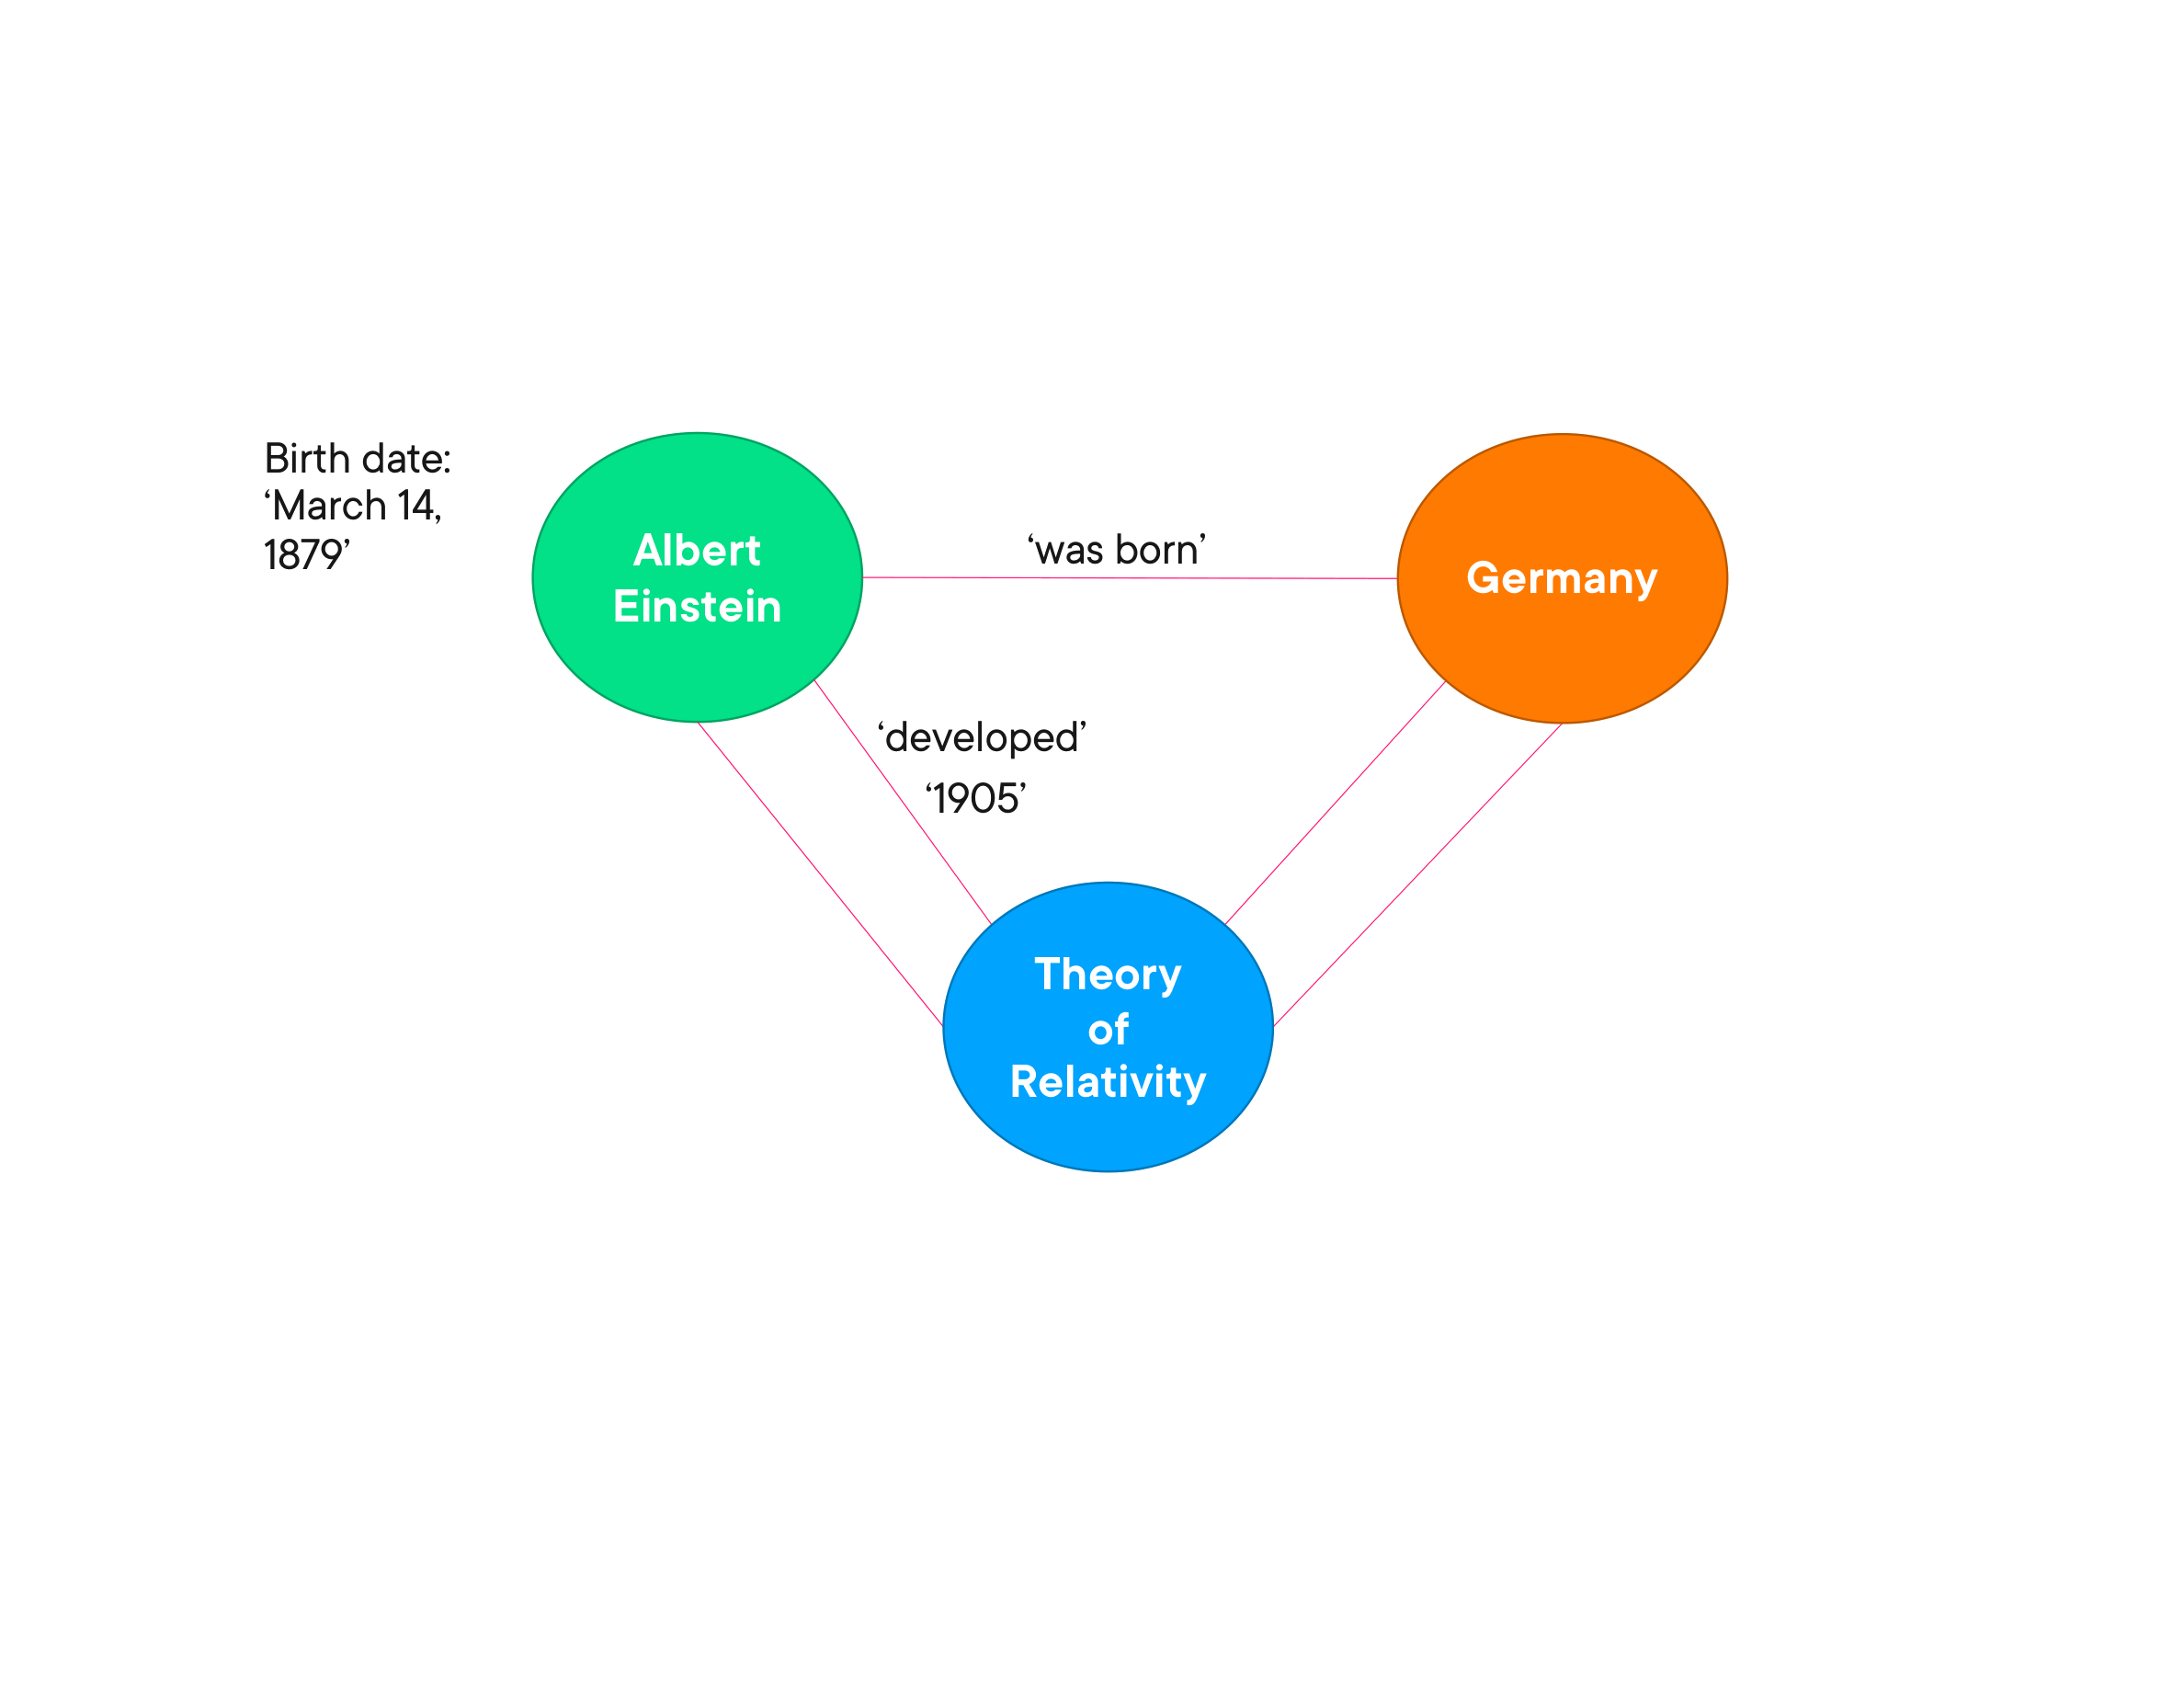

In [10]:
render_diagram(Path("assets/06-knowledge-graph-example.png"))

### Resource Description Framework (RDF)

RDF is the W3C standard for expressing triples. Each triple follows the Subject–Predicate–Object pattern:

```
'Einstein'  hasBirthDate  '1879-03-14'
  Subject      Predicate      Object
```

RDF is the foundation of the **Semantic Web** — a vision of linked data where information published on the web is machine-readable and interconnectable.

### Knowledge Graphs vs. Databases vs. Vector Stores

Each tool fills a different need:


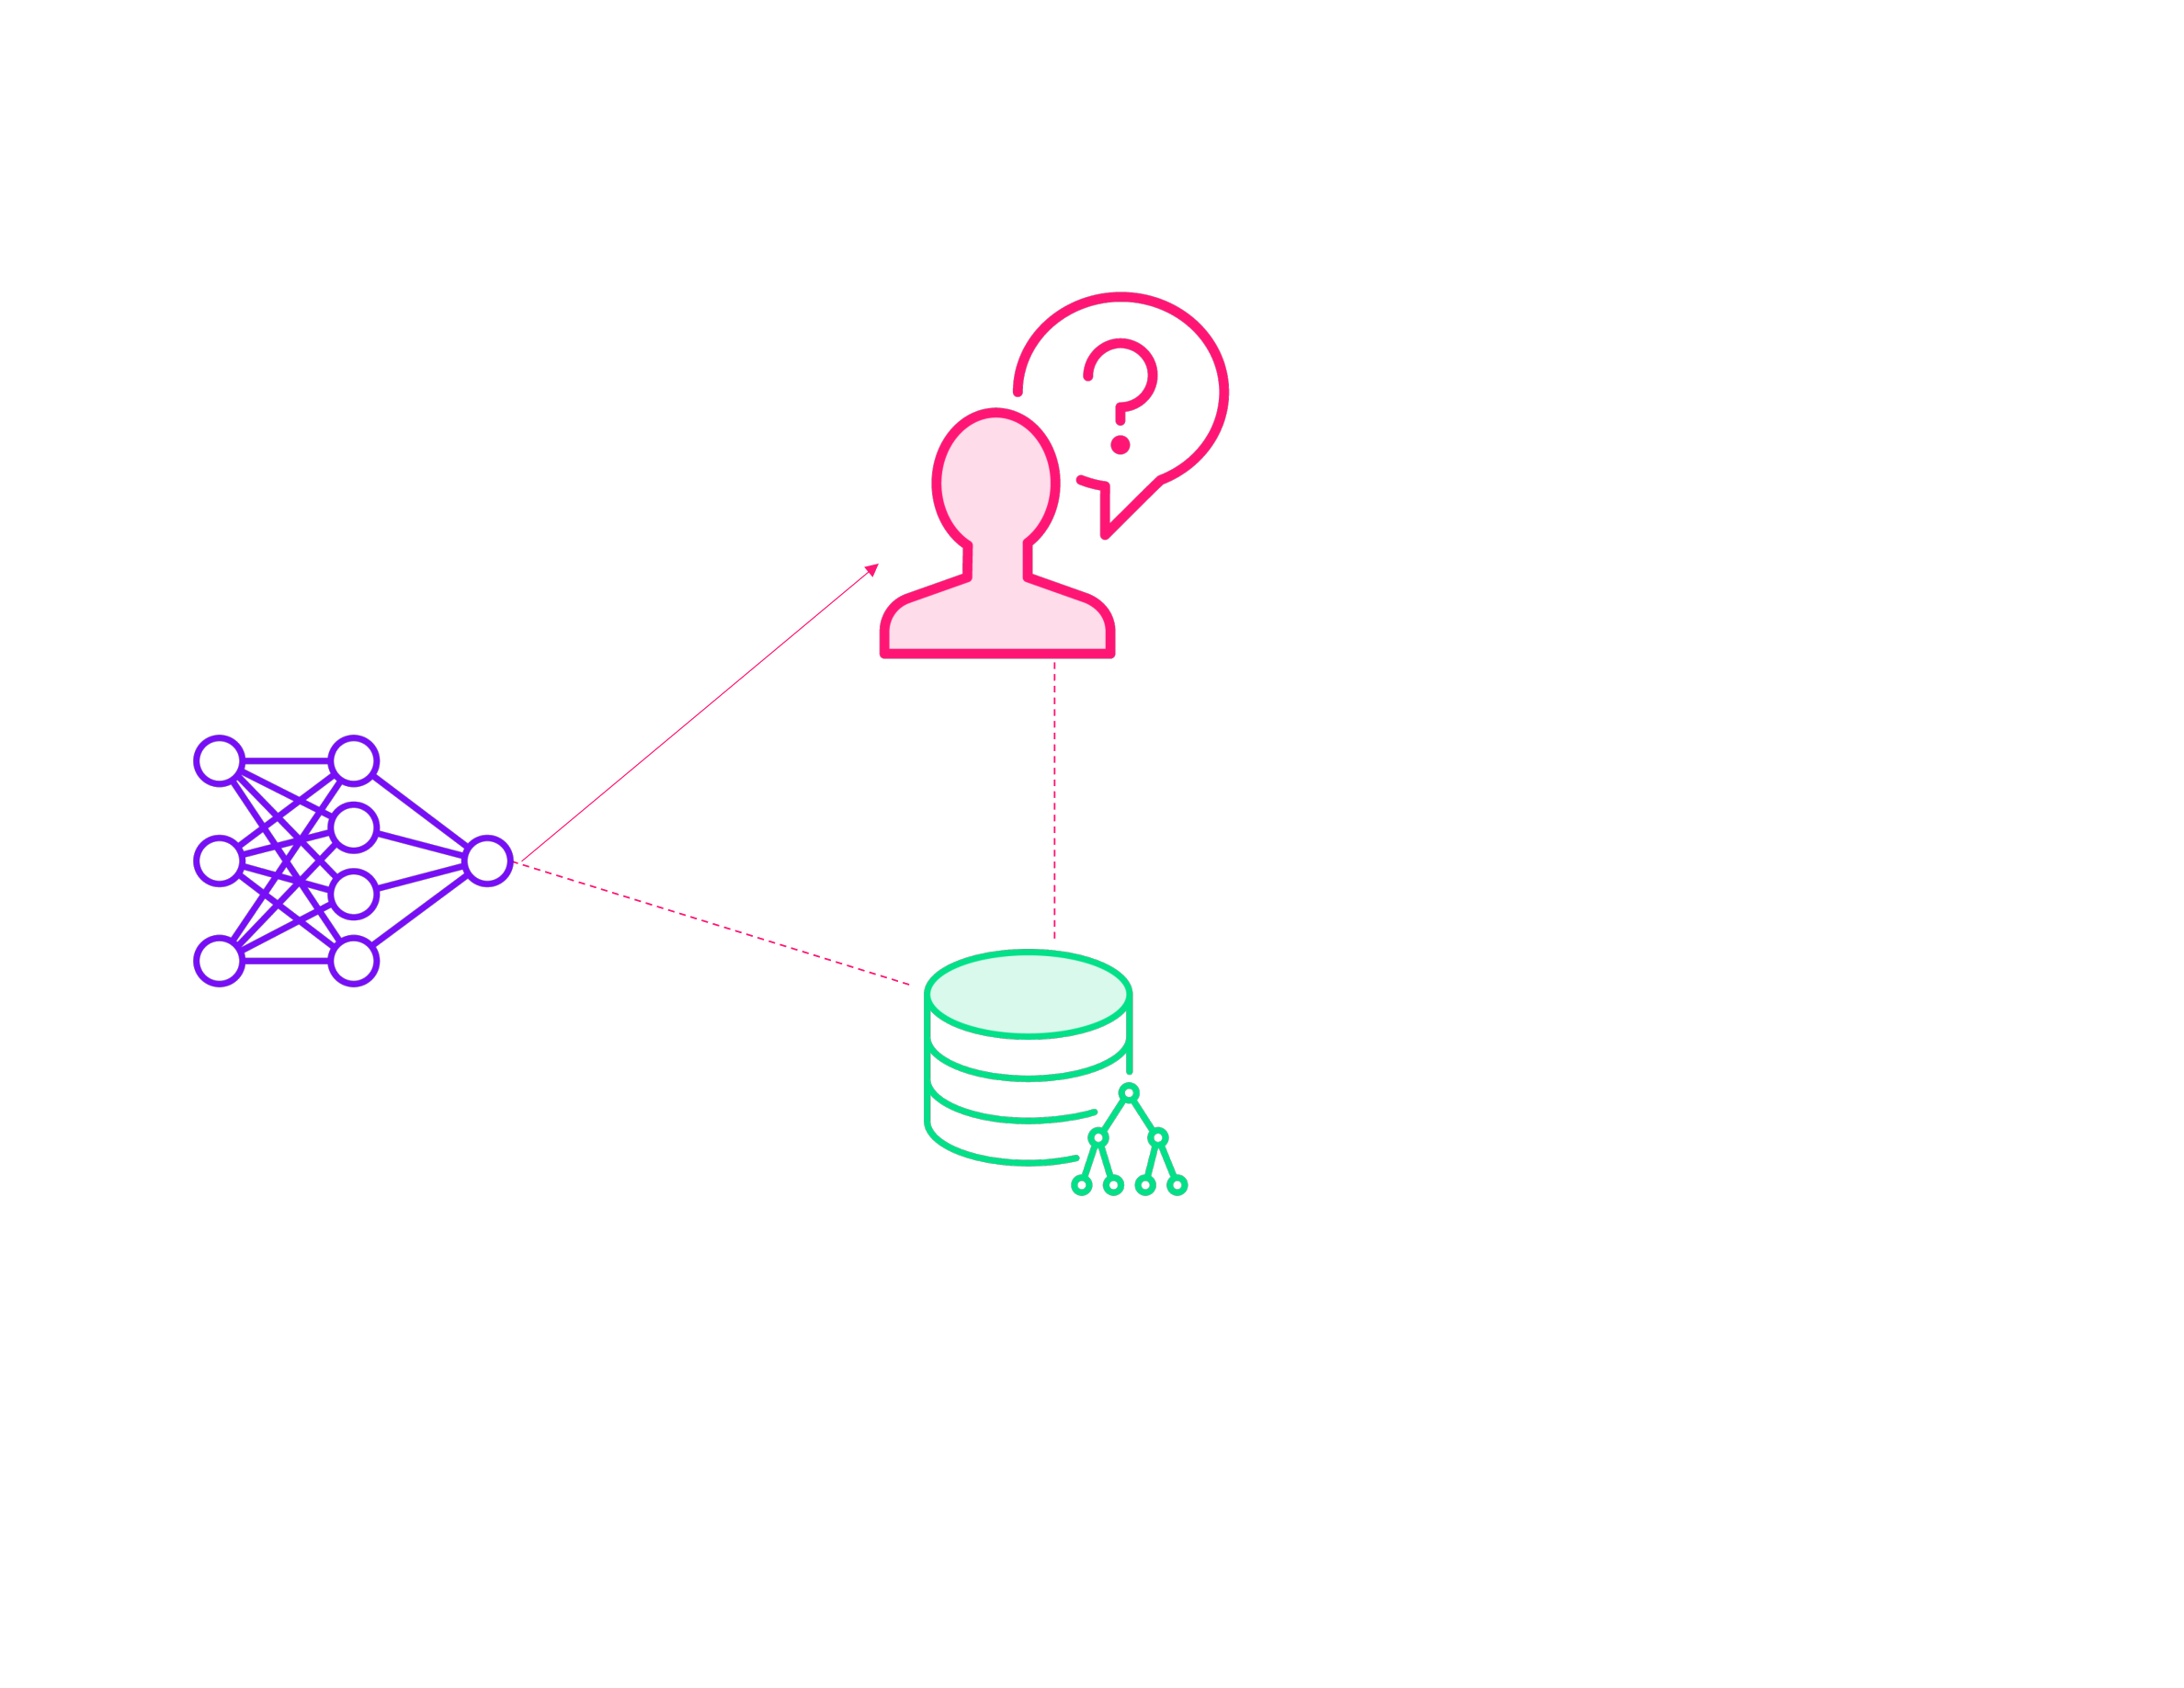

In [11]:
render_diagram(Path("assets/07-rag-vector-graph-architecture.png"))

| | Traditional Database | Vector Store | Knowledge Graph |
|---|---|---|---|
| **Primary query** | Exact matches, predefined queries | Fuzzy semantic similarity | Multi-hop relationship traversal |
| **Data model** | Tables / documents | Embedding vectors | Entities + relationships (triples) |
| **Strengths** | ACID transactions, data integrity | Handles ambiguity of language | Complex reasoning, inference, context |
| **Weaknesses** | Struggles with language ambiguity | No explicit structured relationships | Higher modelling overhead |

**Decision guide**:
- **Traditional database** — transactional records with exact querying.
- **Vector store** — retrieving relevant document chunks for RAG.
- **Knowledge graph** — when the relationships between entities are as important as the entities themselves.

### Ontology and Schema Design

> If the graph data model is like the alphabet, the ontology is the grammar.

An ontology defines:
- **Classes** — categories of things: `Person`, `Organization`, `Event`.
- **Properties** — attributes and relationships: `name`, `birthDate`, `worksFor`.

#### RDF Schema (RDFS)
RDFS lets you define classes and properties and establish simple hierarchies (e.g., `Researcher` is a subclass of `Person`).

#### Web Ontology Language (OWL)
OWL is more expressive than RDFS:
- Express complex logic and constraints.
- Define **disjoint classes** (e.g., `Cat` and `Dog` cannot both be true for the same entity).
- Define **equivalent terms** from different datasets (owl:sameAs).
- **Reasoners** can automatically infer new knowledge from OWL ontologies.

#### Balancing Expressiveness and Performance

In production, heavy OWL reasoning is often replaced with simpler property graph schemas to keep queries fast and scalable. The goal is **"just enough" expressiveness** — model the critical domain distinctions while maintaining query performance.

### Entity Recognition from Unstructured Text

**Named Entity Recognition (NER)** identifies and classifies text spans into categories like organisations, people, and dates.

#### Statistical NER with spaCy
spaCy provides fast, out-of-the-box models trained on news and web data — good baseline for general text.

#### Transformer-based NER
Models like BERT and RoBERTa improve contextual understanding and enable better disambiguation — e.g., distinguishing "Apple" (company) from "apple" (fruit) based on context.

#### Domain-specific Extraction

> Pre-trained models fail when your text is specialized.

Two approaches:
1. **Fine-tune** an existing transformer model on your own labelled data.
2. **Few-shot prompting** — use a large language model with examples of your domain entities.

### Relation Extraction and Knowledge Construction

> Entity recognition answers _what_. Relation extraction answers _how_.

Given a sentence, relation extraction identifies the Subject–Predicate–Object structure:


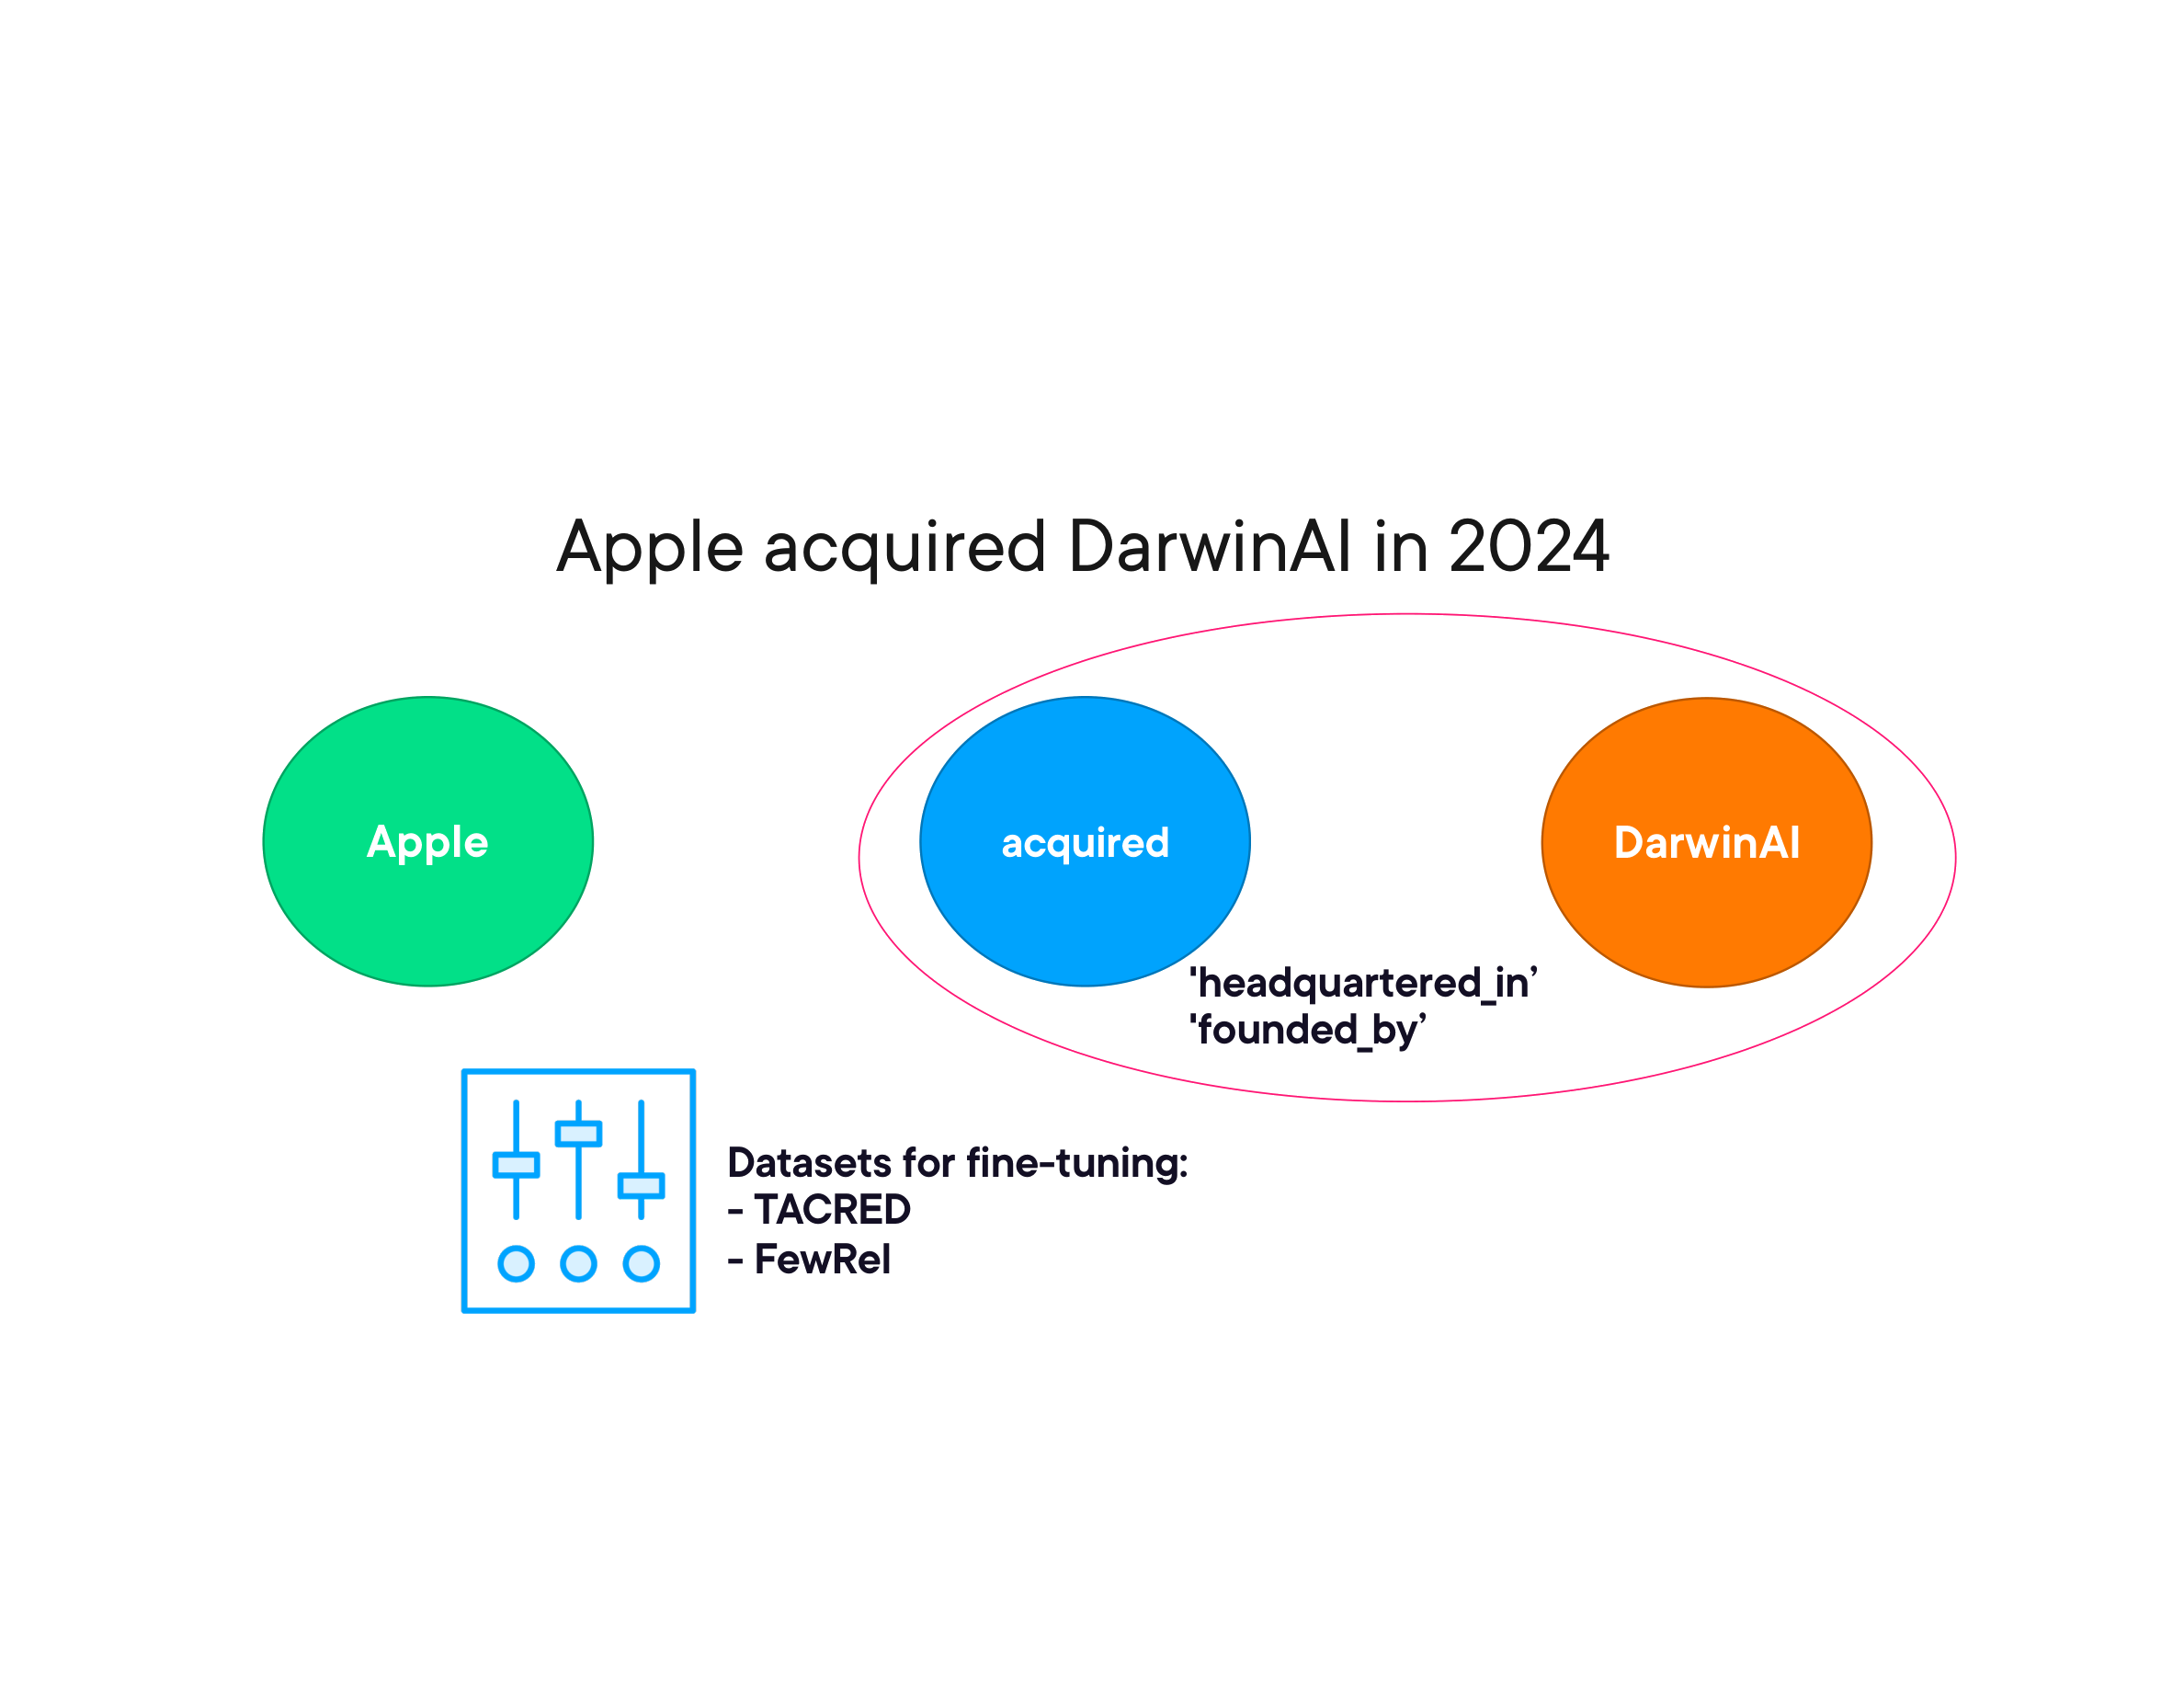

In [12]:
render_diagram(Path("assets/08-relation-extraction-example.png"))

Example:

> _"The research team at Google Brain published the Transformer architecture."_

Extracted triples:
- `(Google Brain, employs, research team)`
- `(research team, published, Transformer architecture)`

Fine-tuning datasets for relation extraction:
- **TACRED** — large-scale relation classification benchmark
- **FewRel** — few-shot relation classification

### Building Knowledge Graphs with LLMs

LLMs can extract entity-relation triples from text in a structured JSON format using few-shot prompting:

In [13]:
# Few-shot prompt template for graph extraction
examples = """
Example 1:
Text: "Satya Nadella is CEO of Microsoft."
Output: {"entities": [{"name": "Satya Nadella", "type": "Person"}, {"name": "Microsoft", "type": "Organization"}],
         "relationships": [{"source": "Satya Nadella", "target": "Microsoft", "type": "CEO_OF"}]}

Example 2:
Text: "Python was created by Guido van Rossum."
Output: {"entities": [{"name": "Python", "type": "Language"}, {"name": "Guido van Rossum", "type": "Person"}],
         "relationships": [{"source": "Guido van Rossum", "target": "Python", "type": "CREATED"}]}
"""

# After extraction, validate the graph for referential integrity
def validate_graph(data):
    entity_names = [e["name"] for e in data["entities"]]
    for rel in data["relationships"]:
        if rel["source"] not in entity_names:
            print(f"Warning: {rel['source']} not in entities")
        if rel["target"] not in entity_names:
            print(f"Warning: {rel['target']} not in entities")
    # Deduplicate entities
    unique = {e["name"]: e for e in data["entities"]}.values()
    data["entities"] = list(unique)
    return data

### Graph Embedding Techniques

Just as text can be embedded into vectors, graph nodes can be embedded — encoding each node's position and connectivity in the graph as a vector.

**Goal**: similar nodes (by graph structure or entity type) → similar vectors.

**Techniques**:
- **Random walks + Word2Vec** — walk the graph randomly, treat node sequences like sentences, apply Word2Vec.
- **Matrix factorization** — decompose the adjacency matrix to find low-rank node representations.
- **Graph Neural Networks (GCNs)** — aggregate neighbourhood information iteratively through learnable transformations.

### Hybrid Retrieval: Vectors and Graph Traversal

> Vector search finds things that _look like_ your query. Graph traversal finds things that are _connected to_ your query.

#### Multi-stage Retrieval

1. **Stage 1** — User asks a question. Each chunk has metadata linking it to entities in the knowledge graph.
2. **Stage 2** — Retrieve with vector similarity *and* traverse the graph from matched entity nodes to find related chunks not textually similar but semantically connected.
3. **Stage 3** — Combine results and re-rank using Reciprocal Rank Fusion (RRF).

Use hybrid retrieval when:
- Your knowledge graph captures relationships not obvious from text alone.
- Users need to discover information through connections (multi-hop queries).

In [14]:
def reciprocal_rank_fusion(vector_results, graph_results, k=60):
    fusion_scores = {}

    for rank, result in enumerate(vector_results):
        doc_id = result['chunk_id']
        fusion_scores[doc_id] = fusion_scores.get(doc_id, 0) + 1 / (rank + k)

    for rank, result in enumerate(graph_results):
        doc_id = result['chunk_id']
        fusion_scores[doc_id] = fusion_scores.get(doc_id, 0) + 1 / (rank + k)

    ranked = sorted(fusion_scores.items(), key=lambda x: x[1], reverse=True)
    return ranked

### Querying Knowledge Graphs

#### SPARQL

SPARQL is SQL for RDF graphs. You write patterns that match subgraphs:

```sparql
PREFIX : <http://example.org/>
SELECT ?company ?year
WHERE {
  :Apple :acquired ?company .
  ?company :foundedIn ?year .
}
```

For transitive queries (all companies acquired directly or indirectly):

```sparql
SELECT ?company WHERE {
  :Apple :acquired+ ?company .  -- the + means one-or-more hops
}
```

#### Cypher (Neo4j)

Cypher is a property graph query language with more expressive path syntax:

```cypher
MATCH (apple:Company {name: 'Apple'})-[:ACQUIRED*]->(company:Company)
RETURN company.name
```

#### Reasoning in Knowledge Graphs

A reasoner infers new facts from ontology rules:
- `acquired ⊆ owns` → acquisitions returned by `owns` queries automatically.
- Transitive relations → `ancestor` can traverse arbitrarily deep hierarchies.
- Equivalent entities → unify identifiers from different datasets (`owl:sameAs`).

### Knowledge Graph Maintenance and Evolution

#### Handling Updates
- Use **incremental updates** — add or modify triples rather than rebuilding the graph.
- Track **provenance** — record which source document each triple came from, enabling targeted updates when a source changes.

#### Duplicate Detection, Schema Evolution, and Versioning

| Task | Strategy |
|---|---|
| **Duplicate detection** | Run nightly jobs; merge entities that refer to the same real-world concept |
| **Schema evolution** | Monitor schema usage to see what new types your data requires |
| **Versioning** | Keep at least a week of snapshots for rollback; test schema changes before applying to production |

### Demos: Knowledge Graph Construction

**Demo: LangChain + OpenAI graph extraction** — Using LangChain and OpenAI to extract entities and relationships from text and build a graph.

**Demo: Graph Neural Networks** — Implementing a simple GCN for node classification.

**Demo: Node embeddings** — Generating node embeddings using random walks.

**Demo: Duplicate entity finding** — Identifying duplicate entities in a knowledge graph using embedding similarity.

See [`02-knowledge-graphs-demos/`](02-knowledge-graphs-demos/) for the full project.

<a id="module-04"></a>

## Module 04: Production Pipelines, Advanced Preprocessing and Synthetic Data

_Covers the architecture of a complete data ingestion pipeline, chunking strategies, multi-modal content handling, metadata enrichment, orchestration with Airflow, and synthetic data generation for testing._

### Pipeline Architecture

A production embedding pipeline has five sequential stages — each responsible for a well-defined transformation:


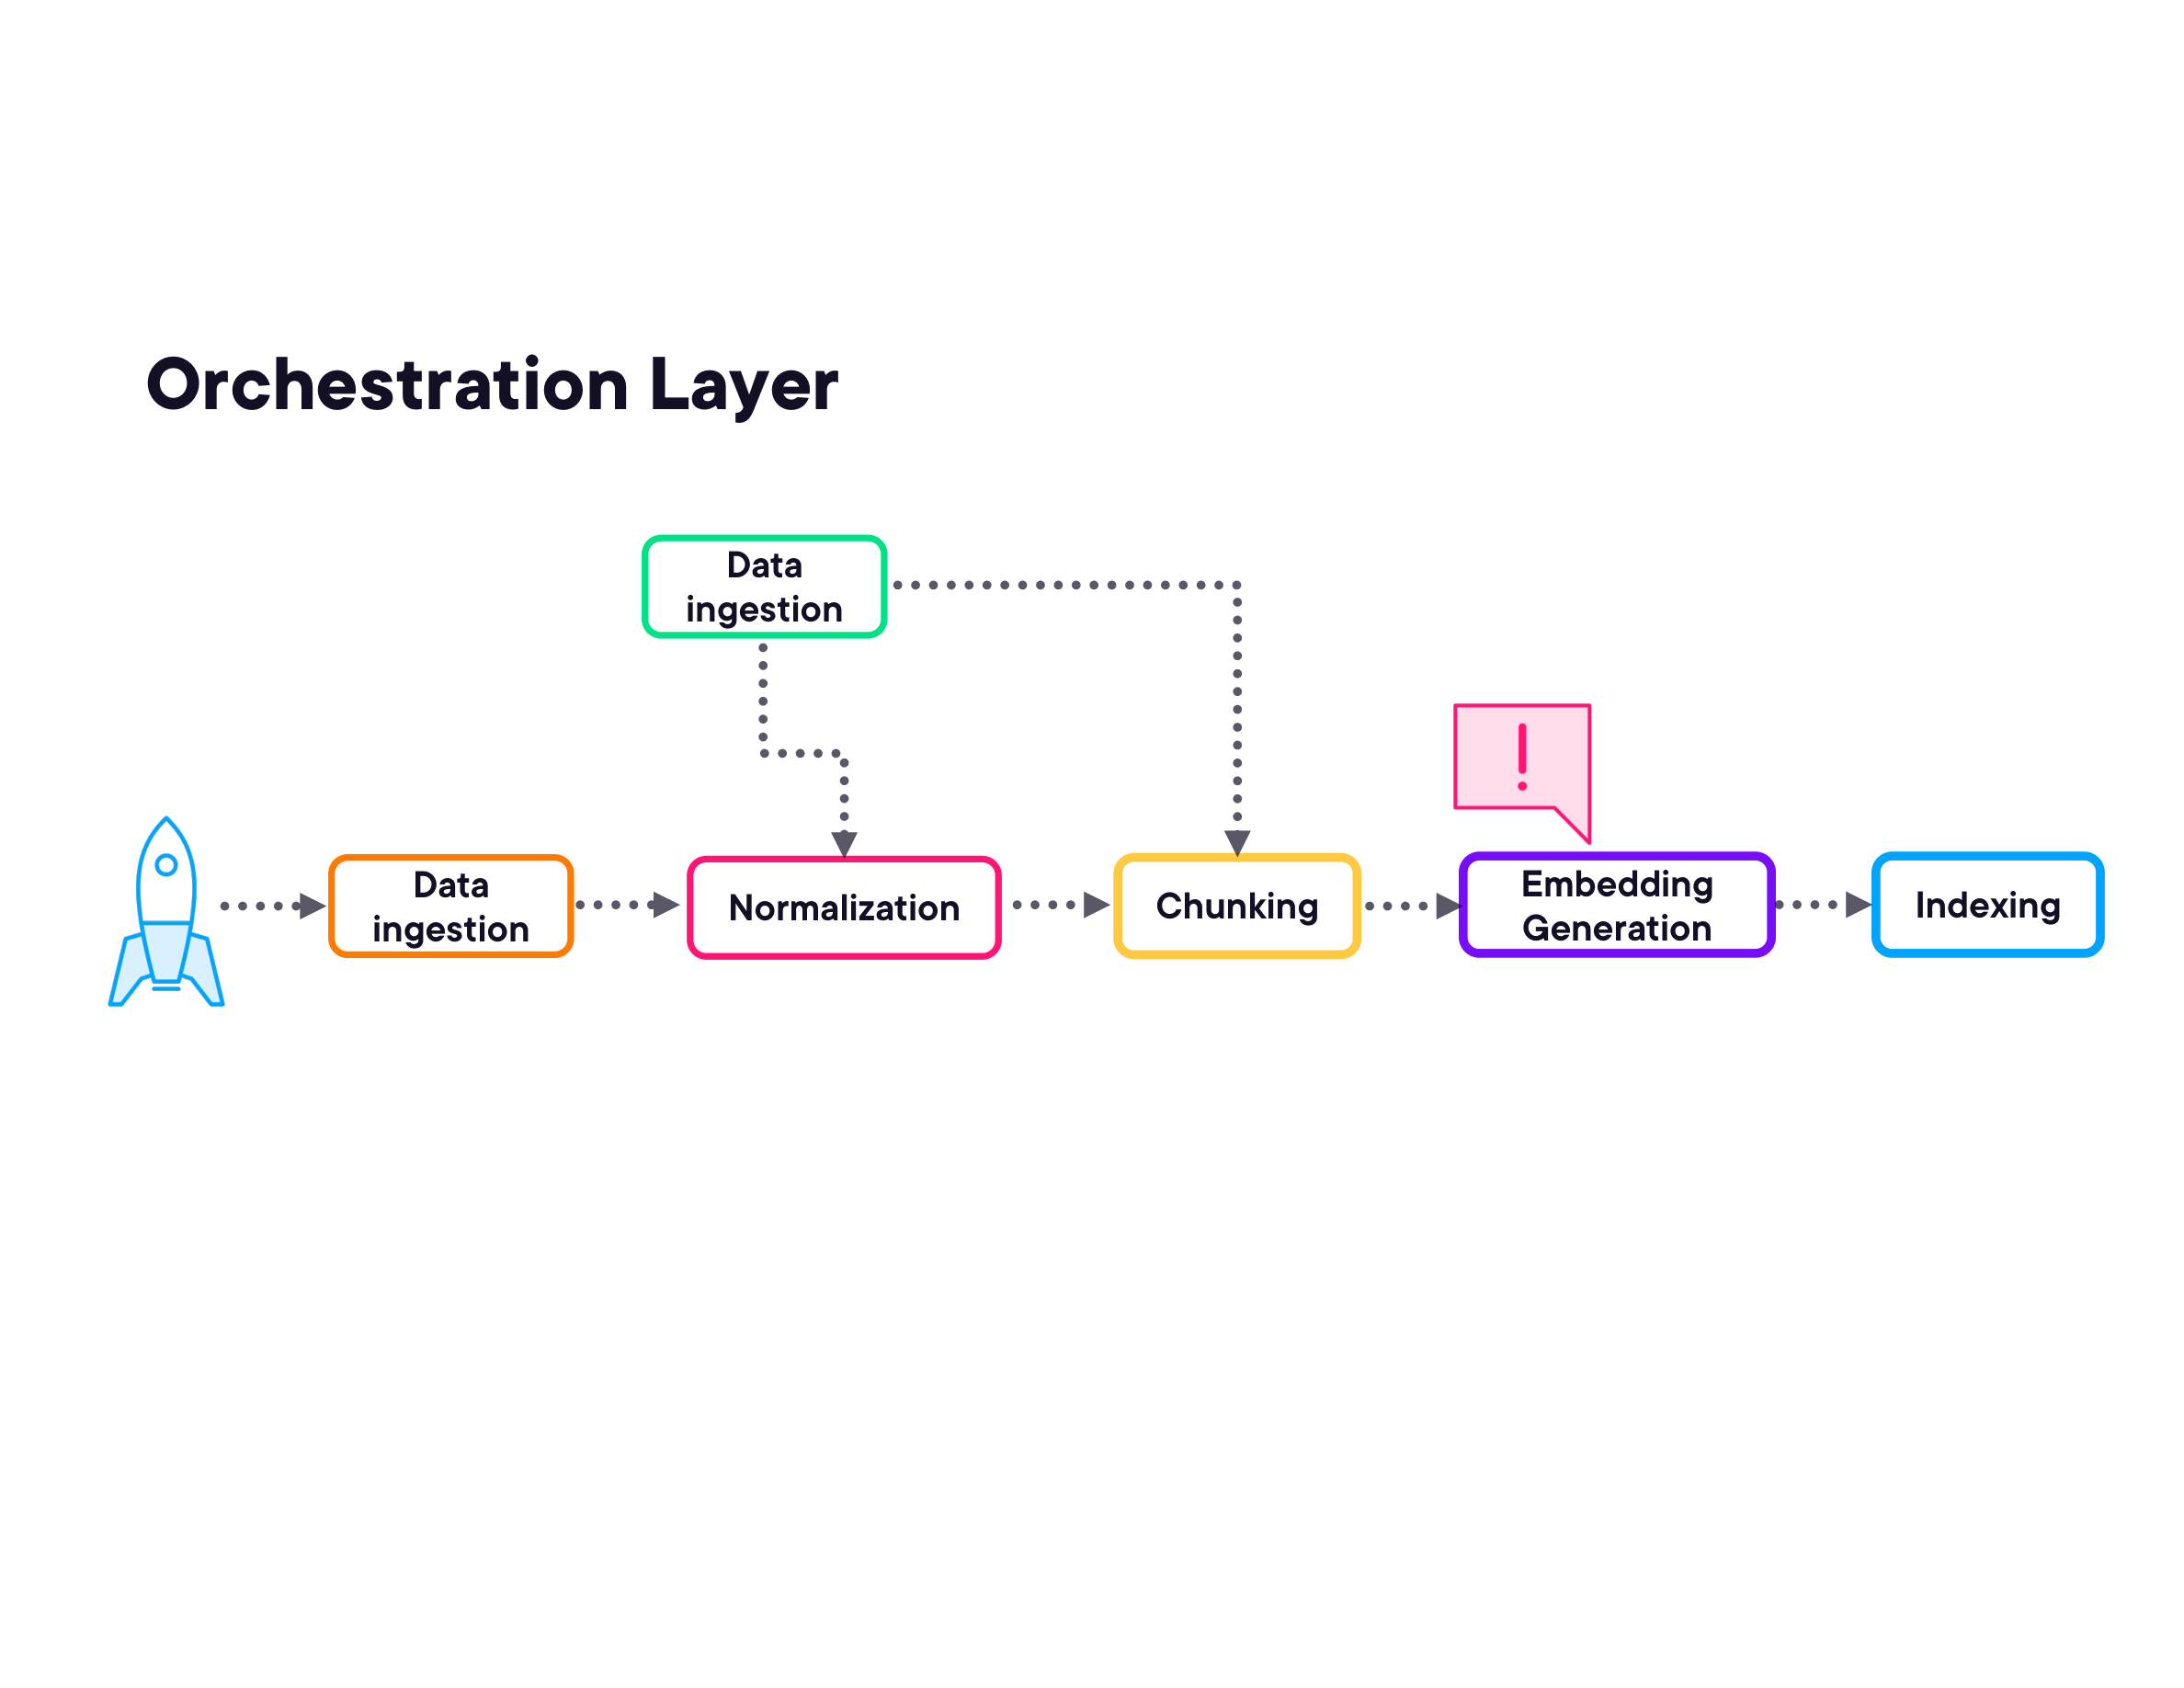

In [15]:
render_diagram(Path("assets/09-pipeline-orchestration-architecture.png"))

| Stage | Responsibility |
|---|---|
| **Data Ingestion** | Connect to data sources; pull new or changed documents (PDFs, Word docs, markdown); handle various file types |
| **Cleaning & Normalisation** | Strip formatting artifacts; extract raw text from complex files; normalise encoding; optionally redact PII |
| **Chunking** | Break large documents into smaller, manageable pieces; enrich chunks with metadata |
| **Embedding Generation** | Turn text into vectors via batch processing with rate limiting and retry logic |
| **Indexing** | Upsert generated vectors into the vector database; manage bulk operations and index updates |

### Chunking Strategies

Chunking is about finding the right granularity:
- **Too large** — one vector tries to represent too much information; retrieval is imprecise.
- **Too small** — high precision but loss of context; retrieved chunks don't make sense in isolation.

#### Fixed-size Chunking
Split text every N tokens or characters, with an optional overlap between consecutive chunks. Simple and predictable.

#### Sentence-based Chunking
Split on sentence boundaries. Preserves semantic units better than fixed-size splits.

#### Recursive Chunking
Try splitting on paragraph boundaries first; if the chunk is still too large, fall back to sentence boundaries, then word boundaries. Respects document structure.

#### Choosing a Chunking Strategy

| Content Type | Recommended Strategy |
|---|---|
| **Prose / long-form text** | Recursive chunking with semantic boundaries |
| **Markdown** | Split on headers |
| **Code** | Split on function / class boundaries |

In [16]:
# From 03-production-pipeline-demos/clip_2_recursive_chunking.py
# from langchain.text_splitter import RecursiveCharacterTextSplitter

# splitter = RecursiveCharacterTextSplitter(
#     chunk_size=500,
#     chunk_overlap=50,
#     separators=["\n\n", "\n", ". ", " ", ""]
# )
# chunks = splitter.split_text(document_text)

### Multi-modal Content Handling

Real documents contain more than plain text — images, tables, and code all require specialised extraction.

#### Images with Text
Use **Optical Character Recognition (OCR)** — Tesseract for local processing, or cloud vision APIs for higher accuracy.

#### Graphs and Photographs
Use vision models such as BLIP or GPT-4o to generate descriptive captions that can be embedded as text.

#### Tables
1. Extract the table as Markdown or JSON.
2. Embed the structured text representation.
3. Create a summary describing the table's content and key insights.

#### Code
- Use a parser to extract function signatures and docstrings.
- Improve retrieval by adding inline comments that explain the code's intent.

#### Indexing Multi-modal Content
Two strategies:
1. **Combine everything** into a single chunk (text + caption + table summary).
2. **Multi-vector indexing** — store separate vectors per modality, link them by document ID.

### Metadata Enrichment and Context Injection

Raw chunks lose context: pronouns like "the company" or "the results" become ambiguous when retrieved out of context.

**Most important metadata to capture**:
- Document title
- Section headers
- Timestamps
- Document type or source category

#### How to Use Metadata

Two complementary approaches:


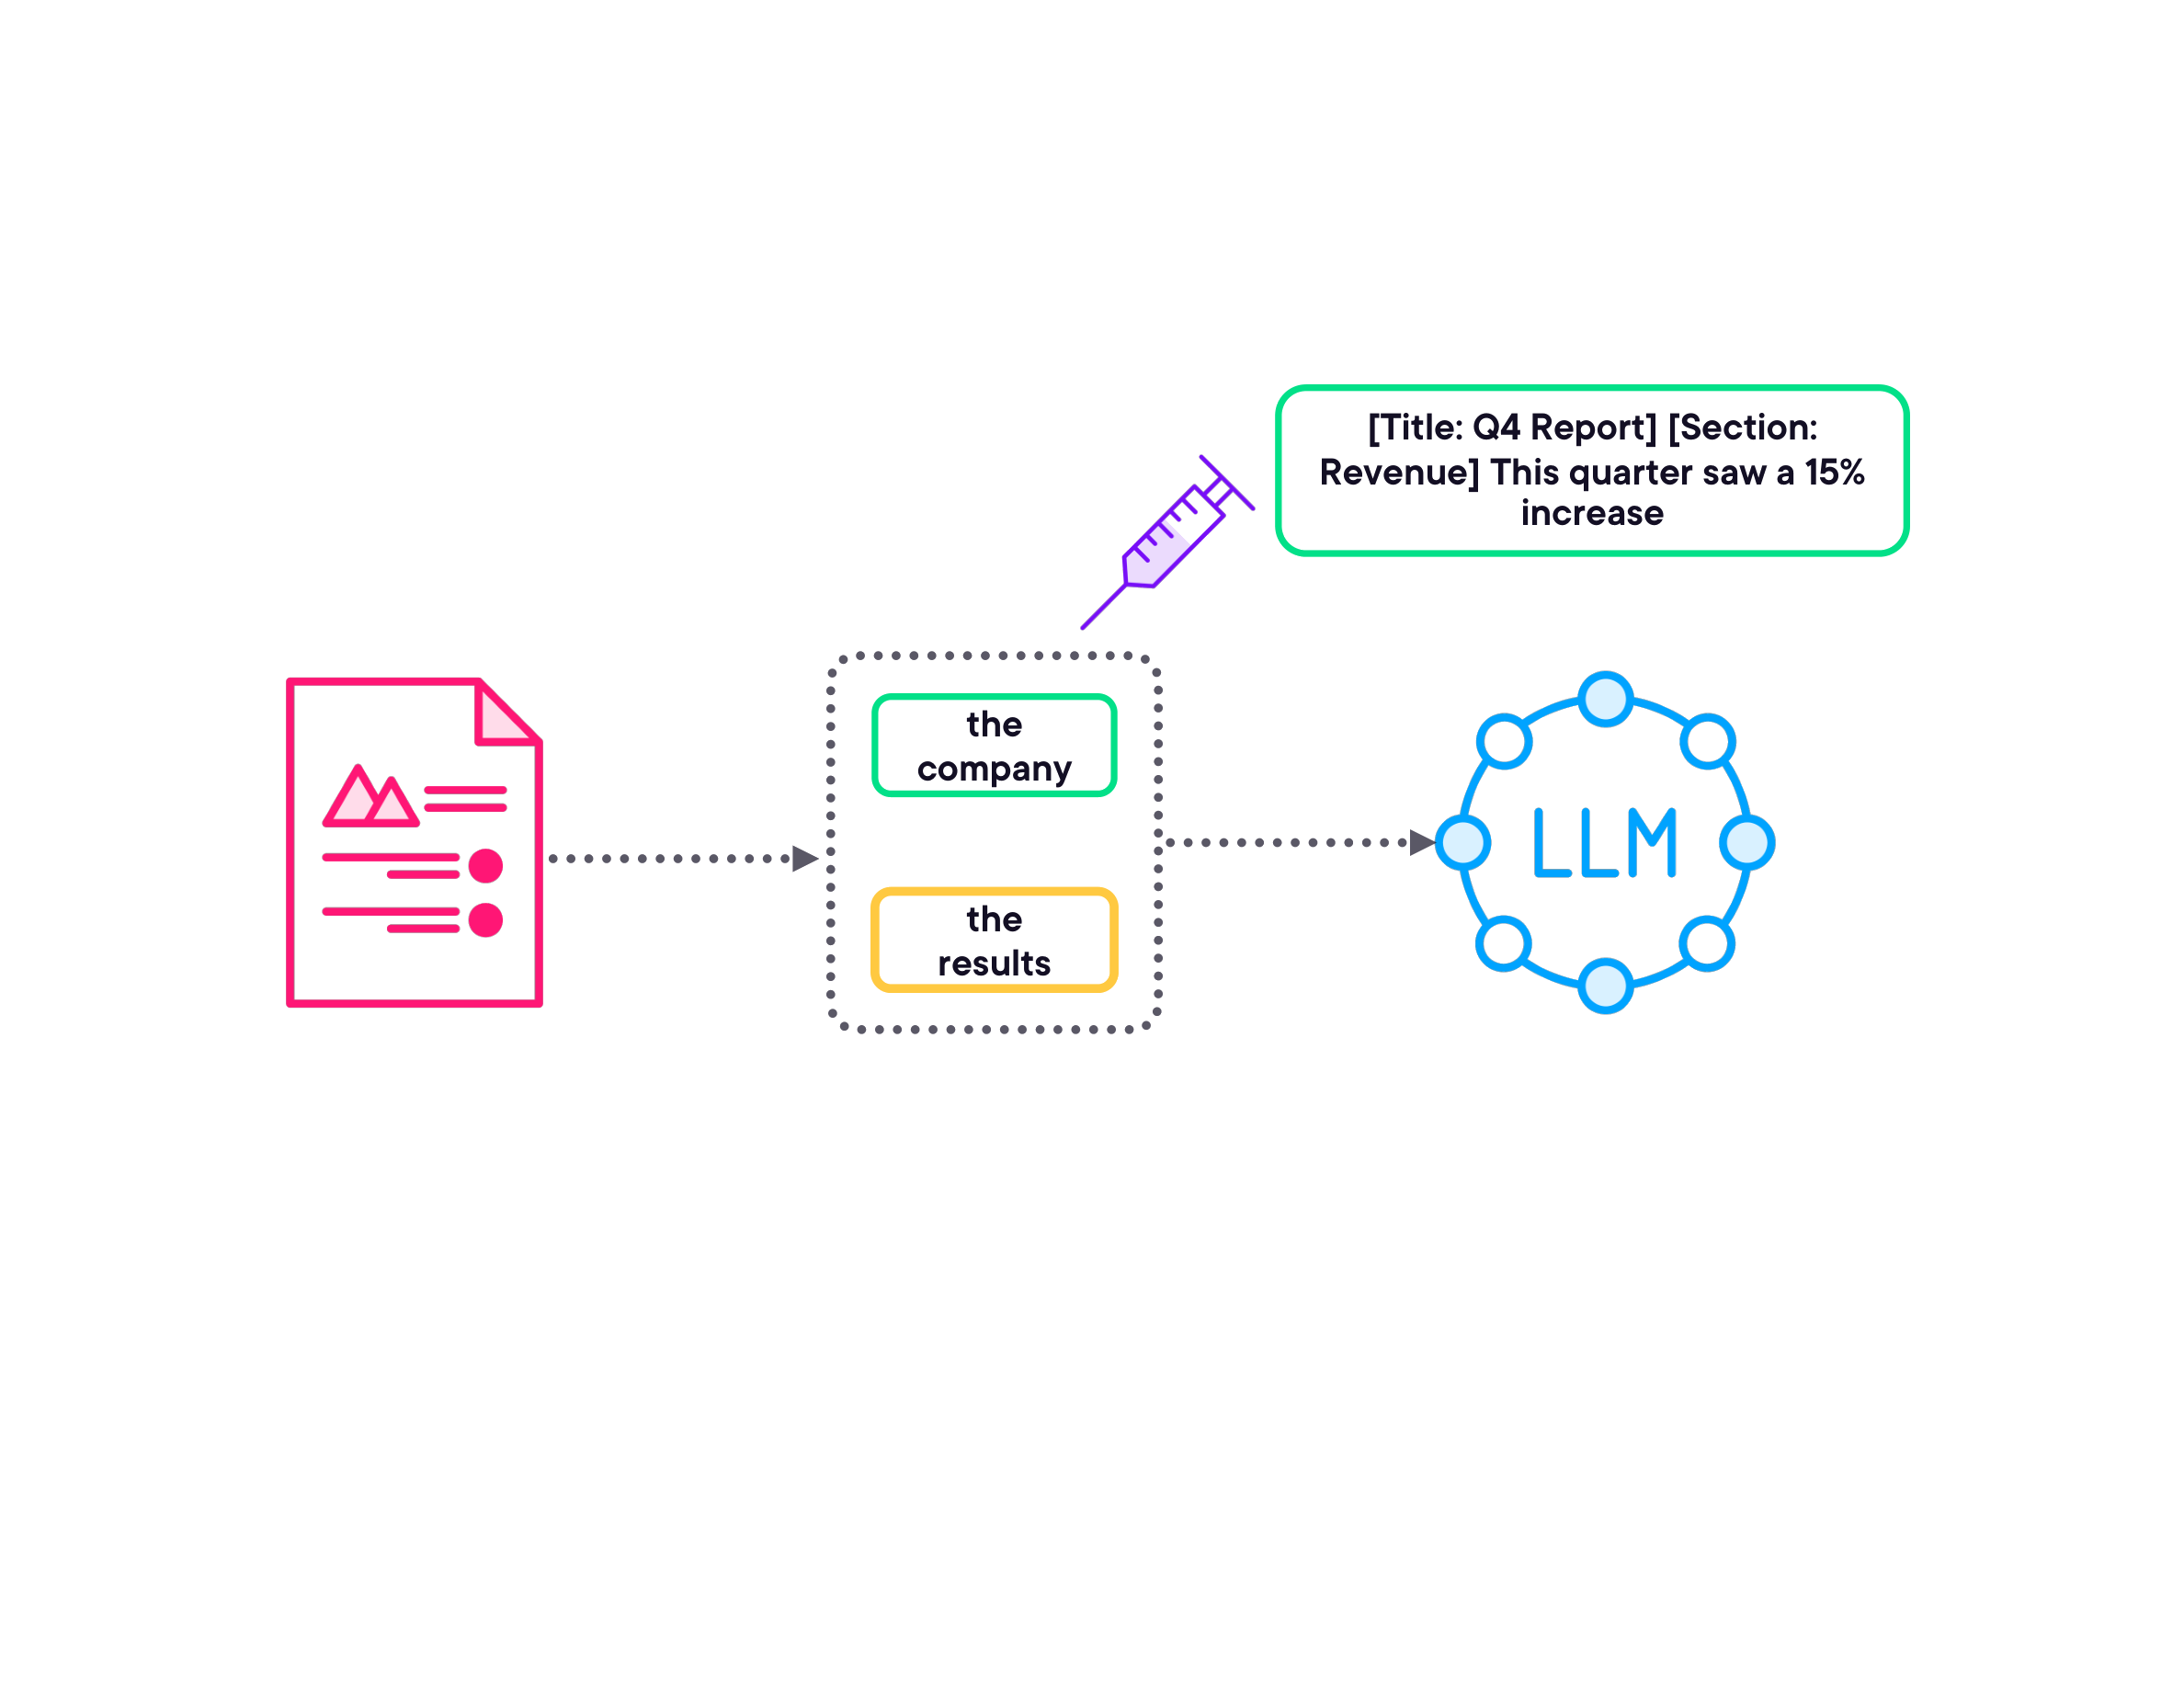

In [17]:
render_diagram(Path("assets/10-metadata-injection-flow.png"))

1. **Context Injection** — prepend metadata directly into the chunk text before embedding:

   ```
   Before: "This quarter saw a 15% increase in revenue"
   After:  "[Title: Q4 Report] [Section: Revenue] This quarter saw a 15% increase in revenue"
   ```

   This makes the chunk self-contained and improves semantic match quality.

2. **Metadata Filtering** — store metadata fields separately alongside the vector for filtered search (e.g., restrict retrieval to documents from a specific date range or source type).

In [18]:
# From 03-production-pipeline-demos/clip_3_metada_enrichment.py
# def enrich_chunk(chunk_text: str, metadata: dict) -> str:
#     prefix = " ".join(f"[{k}: {v}]" for k, v in metadata.items())
#     return f"{prefix} {chunk_text}"

### Orchestrating Pipelines with Airflow

As the pipeline grows, manual execution becomes impractical. Apache Airflow uses the concept of a **DAG (Directed Acyclic Graph)** to:
- Run each task at the right time and in the right order.
- Handle failures gracefully with retry logic.
- Provide visibility into pipeline health via a UI and alerting.

In [19]:
# From 03-production-pipeline-demos/clip_4_orchestration.py
# from airflow import DAG
# from airflow.operators.python import PythonOperator
# from datetime import datetime, timedelta

# default_args = {
#     'owner': 'data_team',
#     'retries': 3,
#     'retry_delay': timedelta(minutes=5),
#     'email_on_failure': True,
# }

# dag = DAG(
#     'embedding_pipeline',
#     default_args=default_args,
#     schedule_interval='@hourly',
#     catchup=False
# )

# Tasks: fetch → normalise → chunk → embed → index
# fetch_task >> clean_task >> chunk_task >> embed_task >> index_task

### Synthetic Data Generation and Testing

One of the biggest challenges in building retrieval systems is **testing** — you need question/answer pairs to evaluate whether your pipeline retrieves the right chunks. Generating these by hand is slow.

**LLM-generated synthetic test data** solves this:


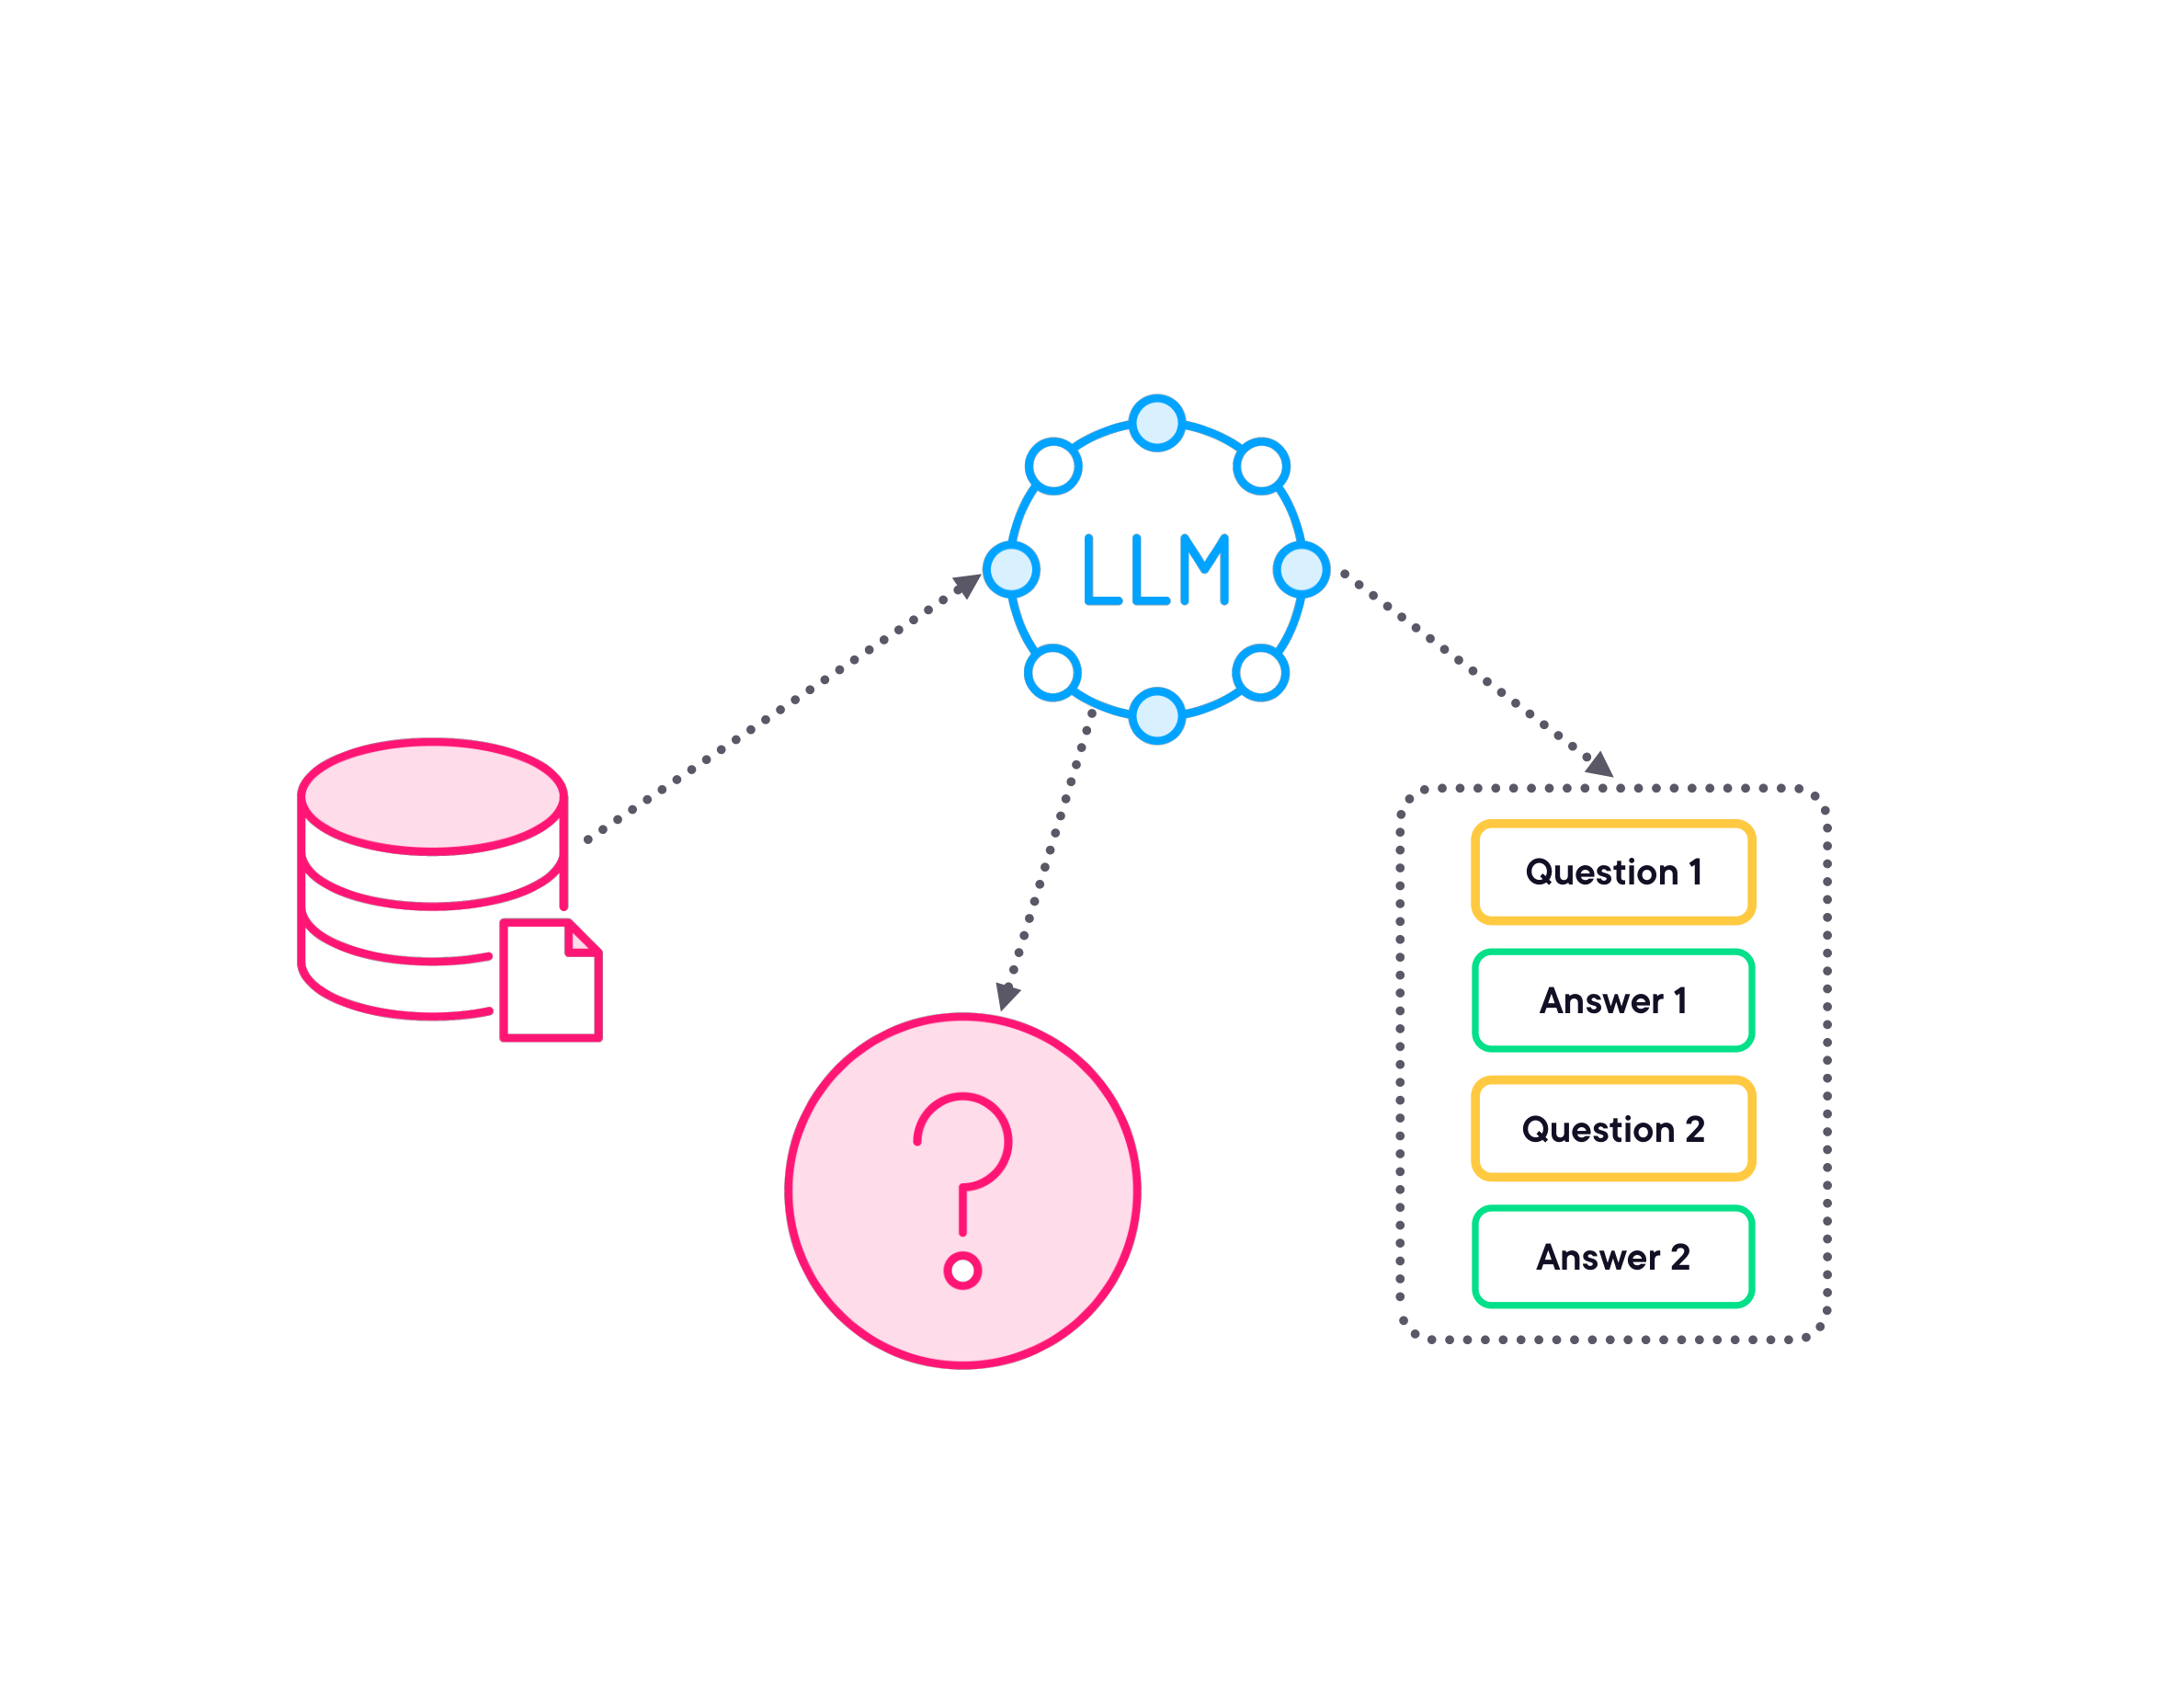

In [20]:
render_diagram(Path("assets/11-synthetic-data-generation.png"))

The pipeline:
1. Feed source documents to an LLM.
2. Ask the LLM to generate realistic questions that can be answered from the document.
3. Also generate the expected answer.
4. Store as (Question, Answer) pairs.

These pairs form your **evaluation dataset** — use them to measure retrieval recall, precision, and answer quality as you tune chunking, embedding models, and index parameters.

In [21]:
# From 03-production-pipeline-demos/clip_5_synthetic_data.py
# def generate_qa_pairs(document_text: str, llm_client, n: int = 5) -> list[dict]:
#     prompt = f"""
#     Given the following document, generate {n} question-answer pairs
#     that test understanding of the key concepts.
#     Return as JSON array: [{{"question": "...", "answer": "..."}}]
#
#     Document:
#     {document_text}
#     """
#     response = llm_client.complete(prompt)
#     return json.loads(response)

### Demos: Production Pipeline Components

**Demo: Fixed, recursive, and sentence chunking** — Comparing the three main chunking strategies on the same document.

**Demo: Metadata enrichment and PDF processing** — Extracting metadata from PDFs and injecting it into chunks before embedding.

**Demo: Airflow DAG orchestration** — A complete Airflow DAG wiring together all pipeline stages with error handling and retries.

**Demo: Synthetic data generation** — Using an LLM to generate question-answer evaluation pairs from source documents.

See [`03-production-pipeline-demos/`](03-production-pipeline-demos/) for the full project.